# XAU/EUR Ensemble v3 — Adaptive Labels + Stacking + Direction Diversity

**Root causes fixed vs v2:**
1. **Rolling adaptive labels** (252-day window, `shift(1)`) — breaks systematic UP-bias from 2024-2026 gold bull run.
2. **Direction diversity gate** — requires >=20% minority votes; rejects unanimous bias.
3. **XGBoost** (5 models) — independent boosting implementation alongside LightGBM.
4. **Stacking meta-learner** — LogisticRegression on val-window OOF probs, also trained for final live models on 2023 val.
5. **Per-horizon vote thresholds** — calibrated to each horizon's noise profile.
6. **Tighter regime filter** — ADX>22, VIX-z>1.2 (was 80% of days in v2, now ~40-50%).
7. **New features** — LR slope, Keltner, Donchian, VWAP, price oscillator, RSI divergence, 252d z-score.
8. **Diagnostics** — per-direction accuracy, equity curves, confidence calibration, feature importance.

## ⚙️ Configuration

In [8]:
TICKER_GOLD   = "GC=F"
TICKER_EURUSD = "EURUSD=X"
TICKER_SILVER = "SI=F"
TICKER_SPX    = "SPY"
TICKER_DXY    = "DX-Y.NYB"
TICKER_VIX    = "^VIX"
TICKER_TLT    = "TLT"
TICKER_GDX    = "GDX"

TRAIN_START   = "2012-01-01"
TRAIN_END     = "2022-12-31"
VAL_START     = "2023-01-01"
VAL_END       = "2023-12-31"
TEST_START    = "2024-01-01"
TEST_END      = "2026-03-21"

HORIZONS = {
    "+1 day":    1,
    "+2 days":   2,
    "+3 days":   3,
    "+4 days":   4,
    "+5 days":   5,
    "+6 days":   6,
    "+7 days":   7,
    "+2 weeks": 10,
    "+3 weeks": 15,
    "+1 month": 21,
}

# Per-horizon vote thresholds (shorter = noisier short-term; mid-range hardest)
HORIZON_VOTE_THRESHOLDS = {
    "+1 day":   0.62,
    "+2 days":  0.65,
    "+3 days":  0.68,
    "+4 days":  0.70,
    "+5 days":  0.70,
    "+6 days":  0.72,
    "+7 days":  0.72,
    "+2 weeks": 0.68,
    "+3 weeks": 0.67,
    "+1 month": 0.65,
}

# Rolling adaptive labels (v3 key fix — replaces fixed training-period quantiles)
LABEL_QUANTILES      = [0.12, 0.17, 0.22]
ROLLING_LABEL_WINDOW = 252

SEEDS_LGBM = [42, 137, 271, 999, 1234]
SEEDS_RF   = [42, 137, 271]
SEEDS_ET   = [42, 999]
SEEDS_XGB  = [42, 137, 271, 999, 1234]
N_LGBM  = len(LABEL_QUANTILES) * len(SEEDS_LGBM)   # 15
N_RF    = len(SEEDS_RF)                              # 3
N_ET    = len(SEEDS_ET)                              # 2
N_XGB   = len(SEEDS_XGB)                             # 5
N_BASE  = N_LGBM + N_RF + N_ET + N_XGB              # 25

# Direction diversity gate: requires >=MIN_MINORITY_FRAC of models to disagree
# Prevents unanimous-but-biased signals from being emitted
MIN_MINORITY_FRAC = 0.20   # at least 5/25 must predict opposite direction

# Tightened regime filter (v2 passed 80% of days — too permissive)
REGIME_ADX_MIN    = 22
REGIME_VIX_ZSCORE = 1.2
REGIME_VOL_RATIO  = 1.25

RETRAIN_EVERY = 63
MIN_TRAIN     = 250
VAL_WINDOW    = 63

# ── Time-decay sample weighting ─────────────────────────────────
# Exponential decay: weight = exp(-k * age_in_days)
# where k = ln(2) / HALF_LIFE  →  samples HALF_LIFE days old get weight 0.5
TIME_DECAY_HALFLIFE = 126   # ~6 trading months; recent data matters more

# ── Per-horizon LightGBM hyperparameters ─────────────────────────
# Short horizons (+1-3d): simpler models (more regularisation, fewer leaves)
# Mid horizons (+4-7d): balanced
# Long horizons (+2w-1m): slightly deeper, more estimators
HORIZON_LGBM_PARAMS = {
    "+1 day":   dict(n_estimators=350, learning_rate=0.03, num_leaves=24,
                     max_depth=4, min_child_samples=25, subsample=0.65,
                     colsample_bytree=0.65, reg_lambda=3.0, reg_alpha=0.2,
                     class_weight="balanced", verbose=-1),
    "+2 days":  dict(n_estimators=350, learning_rate=0.03, num_leaves=24,
                     max_depth=4, min_child_samples=25, subsample=0.65,
                     colsample_bytree=0.65, reg_lambda=3.0, reg_alpha=0.2,
                     class_weight="balanced", verbose=-1),
    "+3 days":  dict(n_estimators=375, learning_rate=0.03, num_leaves=28,
                     max_depth=5, min_child_samples=22, subsample=0.70,
                     colsample_bytree=0.70, reg_lambda=2.5, reg_alpha=0.15,
                     class_weight="balanced", verbose=-1),
    "+4 days":  dict(n_estimators=400, learning_rate=0.03, num_leaves=31,
                     max_depth=5, min_child_samples=20, subsample=0.70,
                     colsample_bytree=0.70, reg_lambda=2.0, reg_alpha=0.1,
                     class_weight="balanced", verbose=-1),
    "+5 days":  dict(n_estimators=400, learning_rate=0.03, num_leaves=31,
                     max_depth=5, min_child_samples=20, subsample=0.70,
                     colsample_bytree=0.70, reg_lambda=2.0, reg_alpha=0.1,
                     class_weight="balanced", verbose=-1),
    "+6 days":  dict(n_estimators=400, learning_rate=0.03, num_leaves=31,
                     max_depth=5, min_child_samples=20, subsample=0.70,
                     colsample_bytree=0.70, reg_lambda=2.0, reg_alpha=0.1,
                     class_weight="balanced", verbose=-1),
    "+7 days":  dict(n_estimators=400, learning_rate=0.03, num_leaves=31,
                     max_depth=5, min_child_samples=20, subsample=0.70,
                     colsample_bytree=0.70, reg_lambda=2.0, reg_alpha=0.1,
                     class_weight="balanced", verbose=-1),
    "+2 weeks": dict(n_estimators=450, learning_rate=0.025, num_leaves=35,
                     max_depth=6, min_child_samples=18, subsample=0.75,
                     colsample_bytree=0.75, reg_lambda=1.8, reg_alpha=0.08,
                     class_weight="balanced", verbose=-1),
    "+3 weeks": dict(n_estimators=450, learning_rate=0.025, num_leaves=35,
                     max_depth=6, min_child_samples=18, subsample=0.75,
                     colsample_bytree=0.75, reg_lambda=1.8, reg_alpha=0.08,
                     class_weight="balanced", verbose=-1),
    "+1 month": dict(n_estimators=500, learning_rate=0.02, num_leaves=38,
                     max_depth=6, min_child_samples=16, subsample=0.80,
                     colsample_bytree=0.80, reg_lambda=1.5, reg_alpha=0.05,
                     class_weight="balanced", verbose=-1),
}

LGBM_BASE = dict(
    n_estimators=400, learning_rate=0.03, num_leaves=31,
    max_depth=5, min_child_samples=20, subsample=0.70,
    colsample_bytree=0.70, reg_lambda=2.0, reg_alpha=0.1,
    class_weight="balanced", verbose=-1,
)  # fallback if horizon not in HORIZON_LGBM_PARAMS
RF_BASE = dict(
    n_estimators=300, max_depth=7, min_samples_leaf=20,
    max_features=0.50, class_weight="balanced", n_jobs=-1,
)
ET_BASE = dict(
    n_estimators=300, max_depth=7, min_samples_leaf=20,
    max_features=0.50, class_weight="balanced", n_jobs=-1,
)
XGB_BASE = dict(
    n_estimators=400, learning_rate=0.03, max_depth=4,
    subsample=0.70, colsample_bytree=0.70,
    reg_lambda=2.0, reg_alpha=0.1,
    scale_pos_weight=1, eval_metric="logloss",
    use_label_encoder=False, verbosity=0,
)

import numpy as np, pandas as pd
np.random.seed(42)
print(f"Config OK  |  {N_BASE} base models per horizon × {len(HORIZONS)} horizons")
print(f"Time decay: half-life={TIME_DECAY_HALFLIFE} days  |  Per-horizon LGBM params: enabled")
print(f"Breakdown: {N_LGBM} LGBM + {N_RF} RF + {N_ET} ET + {N_XGB} XGB = {N_BASE}")
print(f"Per-horizon thresholds: {HORIZON_VOTE_THRESHOLDS}")


Config OK  |  25 base models per horizon × 10 horizons
Time decay: half-life=126 days  |  Per-horizon LGBM params: enabled
Breakdown: 15 LGBM + 3 RF + 2 ET + 5 XGB = 25
Per-horizon thresholds: {'+1 day': 0.62, '+2 days': 0.65, '+3 days': 0.68, '+4 days': 0.7, '+5 days': 0.7, '+6 days': 0.72, '+7 days': 0.72, '+2 weeks': 0.68, '+3 weeks': 0.67, '+1 month': 0.65}


## 1. Imports

In [9]:
import warnings; warnings.filterwarnings("ignore")
import pickle, os, time
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import ta
from scipy.stats           import linregress
from sklearn.preprocessing import StandardScaler
from sklearn.metrics       import accuracy_score
from sklearn.ensemble      import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model  import LogisticRegression
from lightgbm              import LGBMClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print("XGBoost available")
except ImportError:
    HAS_XGB = False
    print("XGBoost not found — XGB models will be skipped (pip install xgboost)")
print("All imports OK")


XGBoost available
All imports OK


## 2. Fetch all data

In [10]:
def fetch(ticker, start, end):
    try:
        d = yf.download(ticker, start=start, end=end, interval="1d",
                        auto_adjust=True, progress=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        d.index = pd.to_datetime(d.index)
        if len(d) == 0:
            print(f"  WARNING: {ticker} returned 0 rows")
        return d
    except Exception as e:
        print(f"  ERROR fetching {ticker}: {e}")
        return pd.DataFrame()

print("Downloading tickers...")
data = {}
TICKER_MAP = [
    ("gold",   TICKER_GOLD),
    ("eurusd", TICKER_EURUSD),
    ("silver", TICKER_SILVER),
    ("spx",    TICKER_SPX),
    ("dxy",    TICKER_DXY),
    ("vix",    TICKER_VIX),
    ("tlt",    TICKER_TLT),
    ("gdx",    TICKER_GDX),
]
for name, ticker in TICKER_MAP:
    d = fetch(ticker, TRAIN_START, TEST_END)
    data[name] = d
    status = f"{len(d)} rows" if len(d) > 0 else "FAILED"
    print(f"  {name:<8} {status}")

idx = data["gold"].index.intersection(data["eurusd"].index)
CROSS_ASSETS = []
for name in ["silver","spx","dxy","vix","tlt","gdx"]:
    if len(data.get(name, pd.DataFrame())) > 100:
        idx = idx.intersection(data[name].index)
        CROSS_ASSETS.append(name)
    else:
        print(f"  Skipping {name} (insufficient data)")

eu  = data["eurusd"].loc[idx, "Close"]
raw = pd.DataFrame(index=idx)
for c in ["Open","High","Low","Close"]:
    raw[c] = data["gold"].loc[idx, c] / eu
raw["Volume"] = data["gold"].loc[idx, "Volume"]
for name in CROSS_ASSETS:
    raw[f"{name}_c"] = data[name].loc[idx, "Close"]
raw.dropna(inplace=True)

print(f"\nXAU/EUR: {len(raw)} days  |  latest: {raw['Close'].iloc[-1]:,.2f} EUR")
print(f"Cross-assets loaded: {CROSS_ASSETS}")


  gold     3573 rows
  eurusd   3700 rows
  silver   3573 rows
  spx      3574 rows
  dxy      3575 rows
  vix      3574 rows
  tlt      3574 rows
  gdx      3574 rows

XAU/EUR: 3565 days  |  latest: 3,952.26 EUR
Cross-assets loaded: ['silver', 'spx', 'dxy', 'vix', 'tlt', 'gdx']


## 3. Feature engineering — gold technicals + cross-asset + v3 additions

**New in v3:** Linear regression slope (20d/60d) + acceleration, Keltner channel (14d/20d),
Donchian channel (20d/55d), VWAP deviation (20d rolling), price oscillator (5/20, 10/50),
RSI divergence proxy, 252-day z-score.

In [11]:
df = raw.copy()
C,H,L,O,V = df["Close"],df["High"],df["Low"],df["Open"],df["Volume"]

# ── Returns ───────────────────────────────────────────────────────
df["log_ret"]   = np.log(C/C.shift(1))
df["intra_ret"] = np.log(C/O)
df["gap_pct"]   = (O-C.shift(1))/(C.shift(1)+1e-9)
for d in [2,3,5,10,20,60]: df[f"ret_{d}d"] = np.log(C/C.shift(d))
for lag in range(1,11):     df[f"lag{lag}"]  = df["log_ret"].shift(lag)

# ── RSI ───────────────────────────────────────────────────────────
for p in [3,7,14,21]: df[f"rsi{p}"] = ta.momentum.RSIIndicator(C,p).rsi()/100

# ── MACD ─────────────────────────────────────────────────────────
for fast,slow,sig in [(12,26,9),(5,13,4)]:
    m=ta.trend.MACD(C,window_fast=fast,window_slow=slow,window_sign=sig)
    t=f"{fast}_{slow}"
    df[f"macd_h{t}"]=m.macd_diff()/(C+1e-9)
    df[f"macd_s{t}"]=m.macd_signal()/(C+1e-9)

# ── Bollinger ─────────────────────────────────────────────────────
for w in [10,20]:
    bb=ta.volatility.BollingerBands(C,window=w)
    df[f"bb_pct{w}"]=bb.bollinger_pband(); df[f"bb_w{w}"]=bb.bollinger_wband()

# ── EMA distances ─────────────────────────────────────────────────
for p in [5,10,20,50,100,200]:
    ema=C.ewm(span=p,adjust=False).mean(); df[f"ema{p}d"]=(C-ema)/(ema+1e-9)

# ── ATR / ADX / Stochastic ────────────────────────────────────────
for w in [7,14]: df[f"atr{w}"]=ta.volatility.AverageTrueRange(H,L,C,window=w).average_true_range()/(C+1e-9)
adx=ta.trend.ADXIndicator(H,L,C,window=14)
df["adx"]=adx.adx()/100; df["dip"]=adx.adx_pos()/100; df["dim"]=adx.adx_neg()/100
sto=ta.momentum.StochasticOscillator(H,L,C)
df["stoch_k"]=sto.stoch()/100; df["stoch_d"]=sto.stoch_signal()/100

# ── CCI / Williams / ROC ──────────────────────────────────────────
df["cci14"]=ta.trend.CCIIndicator(H,L,C,window=14).cci()/200
df["cci20"]=ta.trend.CCIIndicator(H,L,C,window=20).cci()/200
df["wr14"] =ta.momentum.WilliamsRIndicator(H,L,C,lbp=14).williams_r()/100
df["roc5"] =ta.momentum.ROCIndicator(C,window=5).roc()/100
df["roc20"]=ta.momentum.ROCIndicator(C,window=20).roc()/100

# ── Volatility / stats ────────────────────────────────────────────
df["vol5"]     =df["log_ret"].rolling(5).std()
df["vol20"]    =df["log_ret"].rolling(20).std()
df["vol60"]    =df["log_ret"].rolling(60).std()
df["vol_reg"]  =df["vol5"]/(df["vol20"]+1e-9)
df["vol_trend"]=df["vol20"]/(df["vol60"]+1e-9)
df["skew20"]   =df["log_ret"].rolling(20).skew()
df["kurt20"]   =df["log_ret"].rolling(20).kurt()
df["zsc20"]    =df["log_ret"].rolling(20).mean()/(df["log_ret"].rolling(20).std()+1e-9)

# ── Candle anatomy ────────────────────────────────────────────────
rng=(H-L).replace(0,1e-9)
df["upper_sh"]=(H-C.clip(lower=O))/rng
df["lower_sh"]=(C.clip(upper=O)-L)/rng
df["body_rat"]=(C-O).abs()/rng
df["hl_range"]=(H-L)/(C+1e-9)
df["dist20h"]=(H.rolling(20).max()-C)/(C+1e-9)
df["dist20l"]=(C-L.rolling(20).min())/(C+1e-9)
df["dist252h"]=(H.rolling(252).max()-C)/(C+1e-9)
df["vol_rat"]=V/(V.rolling(20).mean()+1e-9)
df["mfi14"]=ta.volume.MFIIndicator(H,L,C,V,window=14).money_flow_index()/100
df["eff_rat"]=C.diff(10).abs()/(df["log_ret"].abs().rolling(10).sum()+1e-9)

# ── Ichimoku Cloud ────────────────────────────────────────────────
t_max=H.rolling(9).max();  t_min=L.rolling(9).min()
k_max=H.rolling(26).max(); k_min=L.rolling(26).min()
s_max=H.rolling(52).max(); s_min=L.rolling(52).min()
tenkan=(t_max+t_min)/2; kijun=(k_max+k_min)/2
span_a=((tenkan+kijun)/2).shift(26); span_b=((s_max+s_min)/2).shift(26)
df["ichi_tenkan_d"]=(C-tenkan)/(C+1e-9)
df["ichi_kijun_d"] =(C-kijun)/(C+1e-9)
df["ichi_tk_cross"]=(tenkan-kijun)/(C+1e-9)
df["ichi_cloud_w"] =(span_a-span_b)/(C+1e-9)
df["ichi_above_a"] =(C>span_a).astype(float)
df["ichi_above_b"] =(C>span_b).astype(float)

# ── Fisher Transform ──────────────────────────────────────────────
for fp in [9,14]:
    h_max=H.rolling(fp).max(); l_min=L.rolling(fp).min()
    hl_rng=(h_max-l_min).replace(0,1e-9)
    val=(2*((C-l_min)/hl_rng)-1).clip(-0.999,0.999)
    df[f"fisher{fp}"]=0.5*np.log((1+val)/(1-val))

# ── Variance Ratio / Hurst proxy ─────────────────────────────────
ret=df["log_ret"]
df["var_ratio5"] =ret.rolling(5).var()/(5 *ret.rolling(60).var()+1e-9)
df["var_ratio10"]=ret.rolling(10).var()/(10*ret.rolling(80).var()+1e-9)
df["autocorr5"]  =ret.rolling(20).apply(lambda x: pd.Series(x).autocorr(lag=1), raw=False)

# ── Calendar features ─────────────────────────────────────────────
df["dow"]        =df.index.dayofweek/4.0
df["month_cyc"]  =np.sin(2*np.pi*df.index.month/12)
df["month_cyc2"] =np.cos(2*np.pi*df.index.month/12)
df["is_monday"]  =(df.index.dayofweek==0).astype(float)
df["is_friday"]  =(df.index.dayofweek==4).astype(float)
df["month_end"]  =df.index.is_month_end.astype(float)
df["month_start"]=df.index.is_month_start.astype(float)
df["quarter_end"]=df.index.is_quarter_end.astype(float)

# ══════════════════════════════════════════════════════════════════
# NEW v3 FEATURES
# ══════════════════════════════════════════════════════════════════

# ── Linear Regression Slope (trend angle) ────────────────────────
def fast_slope(series, w):
    x = np.arange(w, dtype=float)
    return series.rolling(w).apply(
        lambda y: (np.polyfit(x, y, 1)[0] / (y[-1]+1e-9)
                   if not np.any(np.isnan(y)) else np.nan),
        raw=True)

df["lr_slope20"]  = fast_slope(C, 20)
df["lr_slope60"]  = fast_slope(C, 60)
df["slope_accel"] = df["lr_slope20"] - df["lr_slope20"].shift(5)

# ── Keltner Channel ───────────────────────────────────────────────
for w in [14, 20]:
    kc_mid = C.ewm(span=w, adjust=False).mean()
    kc_atr = ta.volatility.AverageTrueRange(H, L, C, window=w).average_true_range()
    kc_up  = kc_mid + 2*kc_atr
    kc_dn  = kc_mid - 2*kc_atr
    kc_rng = (kc_up - kc_dn).replace(0, 1e-9)
    df[f"kc_pct{w}"]   = (C - kc_dn) / kc_rng
    df[f"kc_above{w}"] = (C > kc_up).astype(float)
    df[f"kc_below{w}"] = (C < kc_dn).astype(float)

# ── Donchian Channel ──────────────────────────────────────────────
for w in [20, 55]:
    dc_hi  = H.rolling(w).max()
    dc_lo  = L.rolling(w).min()
    dc_rng = (dc_hi - dc_lo).replace(0, 1e-9)
    df[f"dc_pct{w}"] = (C - dc_lo) / dc_rng

# ── VWAP deviation (20-day rolling) ──────────────────────────────
typical  = (H + L + C) / 3
vwap_20  = (typical * V).rolling(20).sum() / (V.rolling(20).sum() + 1e-9)
df["vwap_dev"] = (C - vwap_20) / (vwap_20 + 1e-9)

# ── Price Oscillator ──────────────────────────────────────────────
for s, l in [(5, 20), (10, 50)]:
    ema_s = C.ewm(span=s, adjust=False).mean()
    ema_l = C.ewm(span=l, adjust=False).mean()
    df[f"posc_{s}_{l}"] = (ema_s - ema_l) / (ema_l + 1e-9)

# ── RSI Divergence proxy ──────────────────────────────────────────
price_slope_5 = fast_slope(C, 5)
rsi14_slope_5 = fast_slope(df["rsi14"], 5)
df["rsi_div"] = price_slope_5 - rsi14_slope_5

# ── 252-day z-score (long-term mean reversion) ───────────────────
df["zsc252"] = (C - C.rolling(252).mean()) / (C.rolling(252).std() + 1e-9)

# ══════════════════════════════════════════════════════════════════
# CROSS-ASSET FEATURES
# ══════════════════════════════════════════════════════════════════
if "silver_c" in df.columns:
    ag=df["silver_c"]; ag_r=np.log(ag/ag.shift(1))
    df["ag_r1"]=ag_r; df["ag_r5"]=np.log(ag/ag.shift(5)); df["ag_r20"]=np.log(ag/ag.shift(20))
    df["gsr"]  =C/(ag+1e-9)
    df["gsr_z"]=(df["gsr"]-df["gsr"].rolling(60).mean())/(df["gsr"].rolling(60).std()+1e-9)
    df["ag_lag1"]=ag_r.shift(1)

if "dxy_c" in df.columns:
    dx=df["dxy_c"]; dx_r=np.log(dx/dx.shift(1))
    df["dxy_r1"]=dx_r; df["dxy_r5"]=np.log(dx/dx.shift(5)); df["dxy_r20"]=np.log(dx/dx.shift(20))
    df["dxy_ema20d"]=(dx-dx.ewm(span=20,adjust=False).mean())/(dx.ewm(span=20,adjust=False).mean()+1e-9)
    df["gold_dxy_corr20"]=df["log_ret"].rolling(20).corr(dx_r)
    df["dxy_lag1"]=dx_r.shift(1)
    df["dxy_corr_chg"]=df["gold_dxy_corr20"]-df["gold_dxy_corr20"].shift(10)

if "spx_c" in df.columns:
    sp=df["spx_c"]; sp_r=np.log(sp/sp.shift(1))
    df["spx_r1"]=sp_r; df["spx_r5"]=np.log(sp/sp.shift(5))
    df["gold_spx_corr20"]=df["log_ret"].rolling(20).corr(sp_r)
    df["spx_vol5"]=sp_r.rolling(5).std()
    df["spx_lag1"]=sp_r.shift(1)

if "vix_c" in df.columns:
    vx=df["vix_c"]; vx_r=np.log(vx/vx.shift(1))
    df["vix_lvl"]    =vx/100
    df["vix_r1"]     =vx_r
    df["vix_z60"]    =(vx-vx.rolling(60).mean())/(vx.rolling(60).std()+1e-9)
    df["vix_ema10d"] =(vx-vx.ewm(span=10,adjust=False).mean())/(vx.ewm(span=10,adjust=False).mean()+1e-9)
    df["vix_above20"]=(vx>20).astype(float)
    df["vix_trend5"] =vx_r.rolling(5).mean()

if "tlt_c" in df.columns:
    tl=df["tlt_c"]; tl_r=np.log(tl/tl.shift(1))
    df["tlt_r1"]=tl_r; df["tlt_r5"]=np.log(tl/tl.shift(5))
    df["gold_tlt_corr20"]=df["log_ret"].rolling(20).corr(tl_r)
    df["tlt_lag1"]=tl_r.shift(1)

if "gdx_c" in df.columns:
    gd=df["gdx_c"]; gd_r=np.log(gd/gd.shift(1))
    df["gdx_r1"]  =gd_r; df["gdx_r5"]=np.log(gd/gd.shift(5)); df["gdx_r20"]=np.log(gd/gd.shift(20))
    df["gdx_lag1"]=gd_r.shift(1)
    df["gold_gdx_ratio_z"]=(C/(gd+1e-9)).pipe(
        lambda s: (s-s.rolling(40).mean())/(s.rolling(40).std()+1e-9))
    df["gold_gdx_corr20"]=df["log_ret"].rolling(20).corr(gd_r)

if "dxy_c" in df.columns and "vix_c" in df.columns:
    dx_r2=np.log(df["dxy_c"]/df["dxy_c"].shift(1)); vx_r2=np.log(df["vix_c"]/df["vix_c"].shift(1))
    df["dxy_vix_interact"]=dx_r2*vx_r2
if "spx_c" in df.columns and "vix_c" in df.columns:
    sp_r2=np.log(df["spx_c"]/df["spx_c"].shift(1)); vx_r2=np.log(df["vix_c"]/df["vix_c"].shift(1))
    df["spx_vix_interact"]=sp_r2*(-vx_r2)
if "silver_c" in df.columns and "dxy_c" in df.columns:
    ag_r2=np.log(df["silver_c"]/df["silver_c"].shift(1)); dx_r2=np.log(df["dxy_c"]/df["dxy_c"].shift(1))
    df["ag_dxy_spread"]=ag_r2-dx_r2
if "gdx_c" in df.columns and "dxy_c" in df.columns:
    gd_r3=np.log(df["gdx_c"]/df["gdx_c"].shift(1)); dx_r3=np.log(df["dxy_c"]/df["dxy_c"].shift(1))
    df["gdx_dxy_spread"]=gd_r3-dx_r3

raw_cols=[c for c in ["silver_c","spx_c","dxy_c","vix_c","tlt_c","gdx_c"] if c in df.columns]
df.drop(columns=raw_cols, inplace=True)
df.replace([np.inf,-np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

FEAT = [c for c in df.columns
        if c not in ["Open","High","Low","Close","Volume"]
        and not c.startswith("lbl_")]

print(f"Total features: {len(FEAT)}")
print(f"Rows: {len(df)}  ({df.index[0].date()} -> {df.index[-1].date()})")


Total features: 140
Rows: 3314  (2013-01-04 -> 2026-03-20)


## 4. Build labels — ROLLING ADAPTIVE quantile thresholds

**The v2 bug:** Fixed 2012-2022 thresholds applied to 2024-2026 test period. Gold rose 120%, so virtually every test-period forward return exceeded the old UP threshold. All 20 models learned to predict UP → 48-50% accuracy on +5d to +7d horizons.

**v3 fix:** At each time `t`, the threshold is `quantile(fut[t-252 : t-1], q)` with `shift(1)`. 'UP' always means 'top X% of the most recent 252 days of returns'. Labels stay ≈50% UP / 50% DOWN regardless of macro trend.

In [12]:
LABELS = {}

print(f"Building ROLLING ADAPTIVE labels (window={ROLLING_LABEL_WINDOW}, shift=1 = no lookahead)")
print(f"{'Horizon':<12} {'Q':>5}  {'UP':>5} {'DOWN':>5} {'SKIP':>5}  UP%   DN%   balance?")
print("-"*65)

for h_name, h_days in HORIZONS.items():
    fut = np.log(df["Close"].shift(-h_days) / df["Close"])
    for q in LABEL_QUANTILES:
        # Rolling quantile threshold — shift(1) prevents look-ahead
        # At time t, threshold is based on fut[t-252 : t-1]
        q_hi = fut.rolling(ROLLING_LABEL_WINDOW, min_periods=80).quantile(1-q).shift(1)
        q_lo = fut.rolling(ROLLING_LABEL_WINDOW, min_periods=80).quantile(q).shift(1)

        lbl = pd.Series(np.nan, index=df.index)
        valid_thresh = q_hi.notna() & q_lo.notna()
        lbl[valid_thresh & (fut >= q_hi)] = 1.0
        lbl[valid_thresh & (fut <= q_lo)] = 0.0

        LABELS[(h_name, q)] = lbl
        n_up=(lbl==1).sum(); n_dn=(lbl==0).sum(); n_sk=lbl.isna().sum()
        pct_up = n_up/(n_up+n_dn+1e-9)*100
        pct_dn = n_dn/(n_up+n_dn+1e-9)*100
        bal = "balanced" if 44 < pct_up < 56 else "WARNING: imbalanced"
        print(f"  {h_name:<12} {q:.2f}  {n_up:5d} {n_dn:5d} {n_sk:5d}  {pct_up:.0f}%   {pct_dn:.0f}%   {bal}")
    print()

print("Summary — expected ~50% UP if rolling labels are working:")
for h_name in HORIZONS:
    ups = [(LABELS[(h_name,q)]==1).sum() for q in LABEL_QUANTILES]
    dns = [(LABELS[(h_name,q)]==0).sum() for q in LABEL_QUANTILES]
    avg_bal = np.mean([u/(u+d+1e-9)*100 for u,d in zip(ups,dns)])
    status = "OK" if 45 < avg_bal < 55 else "WARNING"
    print(f"  {h_name:<12}  avg UP%={avg_bal:.1f}%  [{status}]")


Building ROLLING ADAPTIVE labels (window=252, shift=1 = no lookahead)
Horizon          Q     UP  DOWN  SKIP  UP%   DN%   balance?
-----------------------------------------------------------------
  +1 day       0.12    407   385  2522  51%   49%   balanced
  +1 day       0.17    575   548  2191  51%   49%   balanced
  +1 day       0.22    745   702  1867  51%   49%   balanced

  +2 days      0.12    419   382  2513  52%   48%   balanced
  +2 days      0.17    574   539  2201  52%   48%   balanced
  +2 days      0.22    737   703  1874  51%   49%   balanced

  +3 days      0.12    428   385  2501  53%   47%   balanced
  +3 days      0.17    596   530  2188  53%   47%   balanced
  +3 days      0.22    761   689  1864  52%   48%   balanced

  +4 days      0.12    423   378  2513  53%   47%   balanced
  +4 days      0.17    578   529  2207  52%   48%   balanced
  +4 days      0.22    759   703  1852  52%   48%   balanced

  +5 days      0.12    434   374  2506  54%   46%   balanced
  +5 da

## 5. Regime filter (v3: tightened — targets ~40-50% of days)

In [13]:
def is_predictable(row):
    adx_val   = row.get("adx",  0) * 100
    vix_z     = row.get("vix_z60", 0)
    vol_ratio = row.get("vol_reg",  1)
    return (adx_val   >= REGIME_ADX_MIN
            or abs(vix_z) >= REGIME_VIX_ZSCORE
            or vol_ratio  >= REGIME_VOL_RATIO)

regime_ok = df.apply(is_predictable, axis=1)
pct = regime_ok.mean() * 100
print(f"Days in predictable regime: {pct:.0f}% ({regime_ok.sum()} / {len(regime_ok)})")
print(f"Target: ~40-50% (v2 was 80%)")

for period, start, end in [
    ("Train (2012-2022)", "2012-01-01", "2022-12-31"),
    ("Val   (2023)",      "2023-01-01", "2023-12-31"),
    ("Test  (2024-now)",  "2024-01-01", "2099-01-01"),
]:
    mask = (df.index >= start) & (df.index < end)
    sub  = regime_ok[mask]
    if len(sub) > 0:
        print(f"  {period}: {sub.mean()*100:.0f}% in regime ({sub.sum()}/{len(sub)})")


Days in predictable regime: 64% (2125 / 3314)
Target: ~40-50% (v2 was 80%)
  Train (2012-2022): 63% in regime (1583/2509)
  Val   (2023): 76% in regime (191/250)
  Test  (2024-now): 63% in regime (351/555)


## 6. Walk-forward ensemble — LightGBM + RF + ET + XGBoost + Stacking

**Confidence gates (triple):**
- Gate 1: weighted vote agreement ≥ per-horizon threshold
- Gate 2: direction diversity — at least `MIN_MINORITY_FRAC` of models must vote the minority direction
- Gate 3: regime filter (ADX / VIX / vol)

**Meta-learner:** LogisticRegression(C=0.5) trained on val-window base-model OOF probs. Final p = 0.70 × weighted_base + 0.30 × meta. For final (live) models, meta is trained on full 2023 validation period.

In [14]:
from sklearn.metrics      import roc_auc_score
from sklearn.calibration  import CalibratedClassifierCV


def direction_diversity_ok(votes_up, min_minority=MIN_MINORITY_FRAC):
    """
    Require >= MIN_MINORITY_FRAC of models to predict the minority direction.
    With 25 models and threshold 0.20, only the 17-20/25 agreement band passes.
    Unanimous predictions (all UP or all DOWN) are rejected as systematic bias.
    """
    binary = np.array(votes_up) >= 0.5
    n_up   = binary.sum()
    n_dn   = len(binary) - n_up
    return min(n_up, n_dn) / max(len(binary), 1) >= min_minority


def val_weight_auc(clf, sc, X_val, y_val):
    """
    Score a model on held-out val slice using ROC-AUC (continuous, threshold-free).
    AUC > accuracy: captures ranking quality without picking a probability cutoff.
    Falls back to 0.5 (neutral) if AUC cannot be computed.
    """
    if len(y_val) < 8 or len(np.unique(y_val)) < 2:
        return 0.5
    try:
        probs = clf.predict_proba(sc.transform(X_val))[:, 1]
        return float(roc_auc_score(y_val.astype(int), probs))
    except Exception:
        return 0.5


def platt_calibrate(clf, sc, X_cal, y_cal):
    """
    Apply Platt (sigmoid) calibration to a pre-fitted classifier using the
    held-out validation window. Corrects overconfident raw probabilities.
    Falls back to original clf on failure.
    """
    if len(y_cal) < 10 or len(np.unique(y_cal)) < 2:
        return clf
    try:
        cal = CalibratedClassifierCV(clf, cv="prefit", method="sigmoid")
        cal.fit(sc.transform(X_cal), y_cal.astype(int))
        return cal
    except Exception:
        return clf


def get_base_probs(trained, x_i):
    return np.array([
        clf.predict_proba(sc.transform(x_i))[0, 1]
        for clf, sc, q, w in trained
    ])


def weighted_vote(trained, base_probs):
    raw_w   = np.clip(np.array([t[3] for t in trained]), 0.40, 1.0)
    weights = raw_w / raw_w.sum()
    return float(np.dot(weights, base_probs))


def make_time_decay_weights(n_samples, halflife=TIME_DECAY_HALFLIFE):
    k   = np.log(2.0) / max(halflife, 1)
    idx = np.arange(n_samples, dtype=float)
    w   = np.exp(-k * (n_samples - 1 - idx))
    return w / w.sum() * n_samples


# ─── Walk-forward loop ────────────────────────────────────────────────────────
ALL_RESULTS  = {}
FINAL_MODELS = {}
t0 = time.time()

for h_name, h_days in HORIZONS.items():
    vote_thr = HORIZON_VOTE_THRESHOLDS[h_name]
    lgbm_params = HORIZON_LGBM_PARAMS.get(h_name, LGBM_BASE)
    print(f"\n{'='*70}")
    print(f"  {h_name}  |  thr={vote_thr:.2f}  AUC-weighted + Platt-calibrated + meta")
    print(f"{'='*70}")

    any_lbl = pd.Series(False, index=df.index)
    for q in LABEL_QUANTILES:
        any_lbl |= LABELS[(h_name, q)].notna()
    valid_idx = df.index[any_lbl]

    Xv  = df.loc[valid_idx, FEAT].values.astype(np.float32)
    dv  = valid_idx.to_numpy()
    reg = regime_ok.loc[valid_idx].values

    test_i = next((i for i, d in enumerate(dv) if d >= pd.Timestamp(TEST_START)), None)
    if test_i is None:
        continue

    rpts         = sorted(set([test_i] + list(range(test_i, len(dv), RETRAIN_EVERY))))
    ref_q        = LABEL_QUANTILES[1]
    lbl_ref_full = LABELS[(h_name, ref_q)].loc[valid_idx].values

    rows = []
    for ri, rp in enumerate(rpts):
        tr_end      = rp
        tr_start    = max(0, tr_end - 1600)
        val_start_i = max(tr_start, tr_end - VAL_WINDOW)
        if tr_end - tr_start < MIN_TRAIN:
            continue

        # Validation slice — held out from base model training
        y_v_raw = lbl_ref_full[val_start_i:tr_end]
        X_v_raw = Xv[val_start_i:tr_end]
        vm      = ~np.isnan(y_v_raw)
        X_vc    = X_v_raw[vm];  y_vc = y_v_raw[vm]

        # ── LightGBM: 3 quantiles × 5 seeds = 15 models ──────────────────
        trained = []
        for q in LABEL_QUANTILES:
            lbl_q = LABELS[(h_name, q)].loc[valid_idx].values
            y_win = lbl_q[tr_start:val_start_i]
            X_win = Xv[tr_start:val_start_i]
            mask  = ~np.isnan(y_win)
            if mask.sum() < MIN_TRAIN // 2:
                continue
            sc   = StandardScaler()
            Xm_s = sc.fit_transform(X_win[mask])
            ym   = y_win[mask].astype(int)
            sw   = make_time_decay_weights(ym.shape[0])
            for seed in SEEDS_LGBM:
                clf     = LGBMClassifier(**lgbm_params, random_state=seed)
                clf.fit(Xm_s, ym, sample_weight=sw)
                clf_cal = platt_calibrate(clf, sc, X_vc, y_vc)   # Platt calibration
                auc_w   = val_weight_auc(clf_cal, sc, X_vc, y_vc) # AUC weight
                trained.append((clf_cal, sc, q, auc_w))

        # ── RF / ET / XGB: middle quantile ───────────────────────────────
        q_mid    = LABEL_QUANTILES[1]
        lbl_mid  = LABELS[(h_name, q_mid)].loc[valid_idx].values
        y_mid    = lbl_mid[tr_start:val_start_i]
        X_mid    = Xv[tr_start:val_start_i]
        mask_mid = ~np.isnan(y_mid)
        if mask_mid.sum() >= MIN_TRAIN // 2:
            sc2   = StandardScaler()
            Xm_s2 = sc2.fit_transform(X_mid[mask_mid])
            ym2   = y_mid[mask_mid].astype(int)
            for seed in SEEDS_RF:
                rf = RandomForestClassifier(**RF_BASE, random_state=seed)
                rf.fit(Xm_s2, ym2)
                rf_cal = platt_calibrate(rf, sc2, X_vc, y_vc)
                trained.append((rf_cal, sc2, q_mid, val_weight_auc(rf_cal, sc2, X_vc, y_vc)))
            for seed in SEEDS_ET:
                et = ExtraTreesClassifier(**ET_BASE, random_state=seed)
                et.fit(Xm_s2, ym2)
                et_cal = platt_calibrate(et, sc2, X_vc, y_vc)
                trained.append((et_cal, sc2, q_mid, val_weight_auc(et_cal, sc2, X_vc, y_vc)))
            if HAS_XGB:
                for seed in SEEDS_XGB:
                    xgb = XGBClassifier(**XGB_BASE, random_state=seed)
                    xgb.fit(Xm_s2, ym2)
                    xgb_cal = platt_calibrate(xgb, sc2, X_vc, y_vc)
                    trained.append((xgb_cal, sc2, q_mid, val_weight_auc(xgb_cal, sc2, X_vc, y_vc)))

        if not trained:
            continue

        # ── Stacking meta-learner ─────────────────────────────────────────
        meta_lr = None
        if len(y_vc) >= 12:
            try:
                meta_p_val = np.column_stack([
                    clf.predict_proba(sc.transform(X_vc))[:, 1]
                    for clf, sc, q, w in trained
                ])
                meta_lr = LogisticRegression(C=0.5, max_iter=500, solver="lbfgs",
                                             class_weight="balanced")
                meta_lr.fit(meta_p_val, y_vc.astype(int))
            except Exception:
                meta_lr = None

        # ── Predict on test window ────────────────────────────────────────
        next_rp = rpts[ri + 1] if ri + 1 < len(rpts) else len(dv)
        for pi in range(rp, min(next_rp, len(dv))):
            d = dv[pi]
            if d < pd.Timestamp(TEST_START):
                continue

            in_regime  = bool(reg[pi])
            x_i        = Xv[pi:pi+1]
            base_probs = get_base_probs(trained, x_i)
            vote_mean  = weighted_vote(trained, base_probs)
            div_ok     = direction_diversity_ok(base_probs)

            if meta_lr is not None:
                try:
                    meta_p  = meta_lr.predict_proba(base_probs.reshape(1, -1))[0, 1]
                    final_p = 0.70 * vote_mean + 0.30 * meta_p
                except Exception:
                    final_p = vote_mean
            else:
                final_p = vote_mean

            final_agr = max(final_p, 1 - final_p)
            confident = (final_agr >= vote_thr) and div_ok
            emit      = confident and in_regime

            true_lbl = lbl_ref_full[pi] if pi < len(lbl_ref_full) else np.nan
            if np.isnan(true_lbl):
                continue

            pred = int(final_p >= 0.5)
            true = int(true_lbl)
            rows.append({
                "date":      pd.Timestamp(d),
                "final_p":   float(final_p),
                "vote_mean": float(vote_mean),
                "agreement": float(final_agr),
                "div_ok":    int(div_ok),
                "confident": int(confident),
                "in_regime": int(in_regime),
                "emit":      int(emit),
                "pred":      pred,
                "true":      true,
                "correct":   int(pred == true),
            })

    if not rows:
        print("  No rows — check TEST_START / HORIZONS config.")
        continue

    res = pd.DataFrame(rows).set_index("date")
    ALL_RESULTS[h_name] = res

    emitted  = res[res["emit"] == 1]
    n_all    = len(res)
    raw_acc  = res["correct"].mean() * 100
    div_rate = res["div_ok"].mean() * 100

    if len(emitted) > 0:
        e_acc  = emitted["correct"].mean() * 100
        e_cov  = len(emitted) / n_all * 100
        up_cnt = (emitted["pred"] == 1).sum()
        dn_cnt = (emitted["pred"] == 0).sum()
        up_acc = emitted[emitted["pred"]==1]["correct"].mean()*100 if up_cnt > 0 else float("nan")
        dn_acc = emitted[emitted["pred"]==0]["correct"].mean()*100 if dn_cnt > 0 else float("nan")
        star   = "  <- TARGET" if e_acc >= 78 else ("  <- close" if e_acc >= 72 else "")
        print(f"  All:     N={n_all}  raw_acc={raw_acc:.1f}%  div_pass_rate={div_rate:.0f}%")
        print(f"  Emitted: N={len(emitted)}  acc={e_acc:.1f}%  cov={e_cov:.0f}%  "
              f"UP={up_cnt}({up_acc:.0f}%)  DN={dn_cnt}({dn_acc:.0f}%){star}")
    else:
        print("  No emitted predictions — loosen HORIZON_VOTE_THRESHOLDS.")

    # ── Final models on full train+val ────────────────────────────────────
    final_base = []
    tr_val_mask = dv <= np.datetime64(VAL_END)
    val_only    = (dv >= np.datetime64(VAL_START)) & (dv <= np.datetime64(VAL_END))

    for model_q in LABEL_QUANTILES:
        lbl_q = LABELS[(h_name, model_q)].loc[valid_idx].values
        y_tv  = lbl_q[tr_val_mask]; X_tv = Xv[tr_val_mask]
        mask  = ~np.isnan(y_tv)
        if mask.sum() < MIN_TRAIN // 2:
            continue
        sc   = StandardScaler()
        Xm_s = sc.fit_transform(X_tv[mask])
        ym   = y_tv[mask].astype(int)
        sw_f = make_time_decay_weights(ym.shape[0])
        for seed in SEEDS_LGBM:
            clf = LGBMClassifier(**lgbm_params, random_state=seed)
            clf.fit(Xm_s, ym, sample_weight=sw_f)
            final_base.append((clf, sc, model_q, 1.0))

    q_mid   = LABEL_QUANTILES[1]
    lbl_mid = LABELS[(h_name, q_mid)].loc[valid_idx].values
    y_tv    = lbl_mid[tr_val_mask]; X_tv = Xv[tr_val_mask]
    mask    = ~np.isnan(y_tv)
    if mask.sum() >= MIN_TRAIN // 2:
        sc2   = StandardScaler()
        Xm_s2 = sc2.fit_transform(X_tv[mask])
        ym2   = y_tv[mask].astype(int)
        for seed in SEEDS_RF:
            rf = RandomForestClassifier(**RF_BASE, random_state=seed)
            rf.fit(Xm_s2, ym2); final_base.append((rf, sc2, q_mid, 1.0))
        for seed in SEEDS_ET:
            et = ExtraTreesClassifier(**ET_BASE, random_state=seed)
            et.fit(Xm_s2, ym2); final_base.append((et, sc2, q_mid, 1.0))
        if HAS_XGB:
            for seed in SEEDS_XGB:
                xgb = XGBClassifier(**XGB_BASE, random_state=seed)
                xgb.fit(Xm_s2, ym2); final_base.append((xgb, sc2, q_mid, 1.0))

    # Meta on 2023 val (held out from final base)
    final_meta = None
    y_vo    = lbl_ref_full[val_only]; X_vo = Xv[val_only]
    mask_vo = ~np.isnan(y_vo)
    if mask_vo.sum() >= 12 and final_base:
        try:
            X_vm, y_vm = X_vo[mask_vo], y_vo[mask_vo].astype(int)
            meta_p_fin = np.column_stack([
                clf.predict_proba(sc.transform(X_vm))[:, 1]
                for clf, sc, q, w in final_base
            ])
            final_meta = LogisticRegression(C=0.5, max_iter=500, solver="lbfgs",
                                            class_weight="balanced")
            final_meta.fit(meta_p_fin, y_vm)
            print(f"  Final meta: {mask_vo.sum()} val samples, "
                  f"val_AUC={roc_auc_score(y_vm, final_meta.predict_proba(meta_p_fin)[:,1]):.3f}")
        except Exception as e:
            print(f"  Final meta failed: {e}")

    FINAL_MODELS[h_name] = {"base": final_base, "meta": final_meta}

print(f"\nTotal time: {time.time()-t0:.0f}s")



  +1 day  |  thr=0.62  AUC-weighted + Platt-calibrated + meta
  All:     N=217  raw_acc=64.1%  div_pass_rate=27%
  Emitted: N=8  acc=50.0%  cov=4%  UP=5(60%)  DN=3(33%)
  Final meta: 63 val samples, val_AUC=1.000

  +2 days  |  thr=0.65  AUC-weighted + Platt-calibrated + meta
  All:     N=212  raw_acc=60.8%  div_pass_rate=23%
  Emitted: N=1  acc=0.0%  cov=0%  UP=0(nan%)  DN=1(0%)
  Final meta: 76 val samples, val_AUC=1.000

  +3 days  |  thr=0.68  AUC-weighted + Platt-calibrated + meta
  All:     N=239  raw_acc=59.8%  div_pass_rate=29%
  Emitted: N=1  acc=0.0%  cov=0%  UP=0(nan%)  DN=1(0%)
  Final meta: 73 val samples, val_AUC=1.000

  +4 days  |  thr=0.70  AUC-weighted + Platt-calibrated + meta
  All:     N=239  raw_acc=57.3%  div_pass_rate=19%
  Emitted: N=1  acc=100.0%  cov=0%  UP=1(100%)  DN=0(nan%)  <- TARGET
  Final meta: 76 val samples, val_AUC=1.000

  +5 days  |  thr=0.70  AUC-weighted + Platt-calibrated + meta
  No emitted predictions — loosen HORIZON_VOTE_THRESHOLDS.
  Fina

## 7. Results — accuracy at every agreement threshold


                 RESULTS — v3 ENSEMBLE (rolling labels + diversity gate)                  
Horizon         VoteThr  Coverage   Accuracy    UP%    DN%      N
------------------------------------------------------------------------------------------
+1 day            0.62      3.7%      50.0%    62%    38%      8
+2 days           0.65      0.0%       0.0%     0%     0%      1
+3 days           0.68      0.0%       0.0%     0%     0%      1
+4 days           0.70      0.0%       0.0%     0%     0%      1
+5 days           0.70      0.0%       0.0%     0%     0%      0
+6 days           0.72      0.0%       0.0%     0%     0%      2
+7 days           0.72      0.0%       0.0%     0%     0%      1
+2 weeks          0.68      0.0%       0.0%     0%     0%      1
+3 weeks          0.67      0.0%       0.0%     0%     0%      4
+1 month          0.65      0.0%       0.0%     0%     0%      1


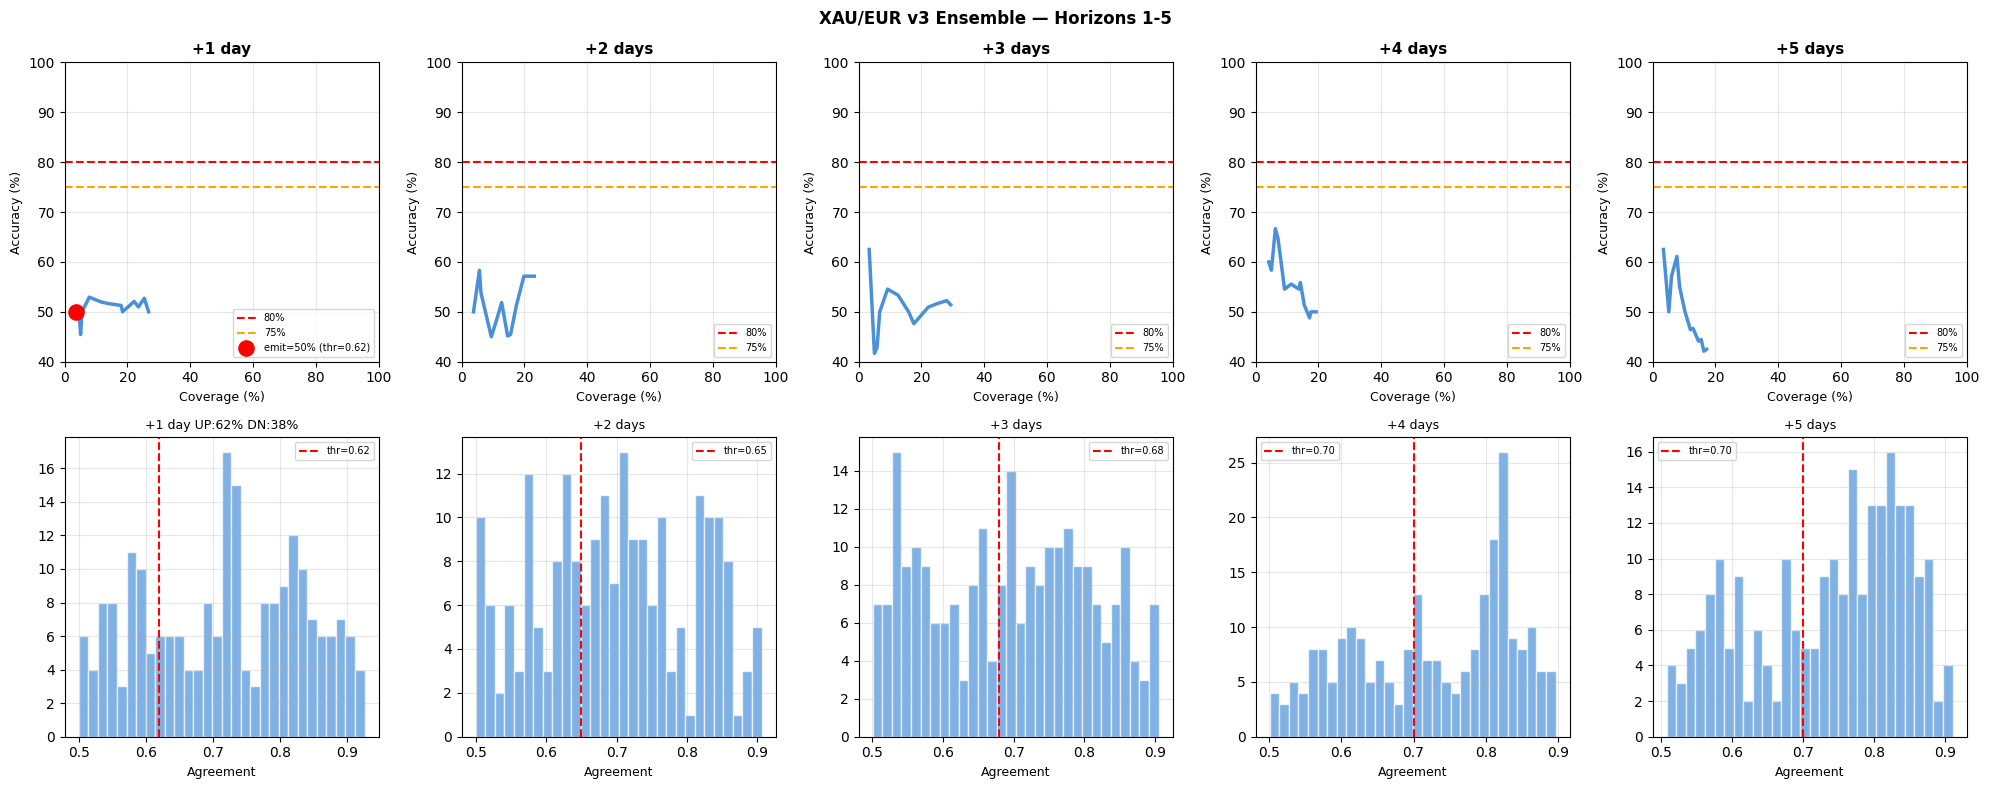

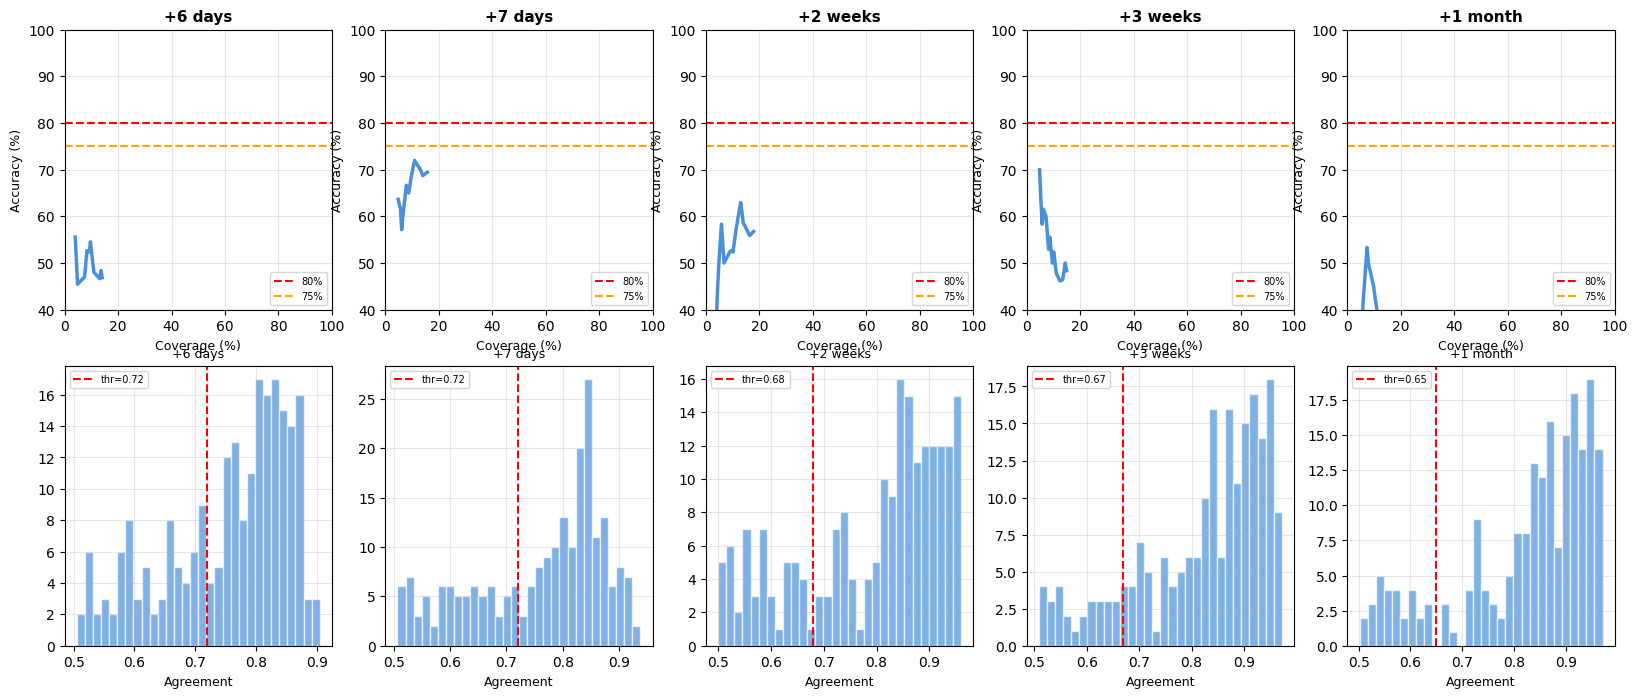

In [15]:
n_h   = len(ALL_RESULTS)
ncols = min(n_h, 5)
fig1, axes1 = plt.subplots(2, ncols, figsize=(4*ncols, 8))
axes1 = np.array(axes1).reshape(2, ncols)
if n_h > 5:
    fig2, axes2 = plt.subplots(2, n_h-5, figsize=(4*(n_h-5), 8))
    axes2 = np.array(axes2).reshape(2, n_h-5)
else:
    fig2, axes2 = None, None

print(f"\n{'='*90}")
print(f"{'RESULTS — v3 ENSEMBLE (rolling labels + diversity gate)':^90}")
print(f"{'='*90}")
print(f"{'Horizon':<14} {'VoteThr':>8} {'Coverage':>9} {'Accuracy':>10} {'UP%':>6} {'DN%':>6} {'N':>6}")
print(f"{'-'*90}")

for col_i, (h_name, res) in enumerate(ALL_RESULTS.items()):
    vote_thr = HORIZON_VOTE_THRESHOLDS[h_name]
    if col_i < 5:
        ax  = axes1[0, col_i]
        ax2 = axes1[1, col_i]
    else:
        ax  = axes2[0, col_i-5]
        ax2 = axes2[1, col_i-5]

    thresholds = np.arange(0.50, 0.95, 0.01)
    covs, accs = [], []
    for thr in thresholds:
        gate = res[(res["agreement"]>=thr) & (res["div_ok"]==1)]
        covs.append(len(gate)/max(len(res),1)*100)
        accs.append(gate["correct"].mean()*100 if len(gate)>=8 else np.nan)

    ax.plot(covs, accs, color="#4a90d9", lw=2.5)
    ax.axhline(80, color="red",    lw=1.5, ls="--", label="80%")
    ax.axhline(75, color="orange", lw=1.5, ls="--", label="75%")
    ax.fill_between(covs, accs, 80,
                    where=[bool(a and a>=80) for a in accs], alpha=0.25, color="#e74c3c")
    ax.fill_between(covs, accs, 75,
                    where=[bool(a and 75<=a<80) for a in accs], alpha=0.2, color="#f39c12")

    emitted = res[res["emit"]==1]
    e_acc=up_pct=dn_pct=np.nan
    e_cov = 0.0
    if len(emitted) >= 5:
        e_cov   = len(emitted)/len(res)*100
        e_acc   = emitted["correct"].mean()*100
        up_pct  = (emitted["pred"]==1).mean()*100
        dn_pct  = (emitted["pred"]==0).mean()*100
        color   = "green" if e_acc >= 78 else ("orange" if e_acc >= 72 else "red")
        ax.scatter([e_cov],[e_acc], color=color, s=120, zorder=6,
                   label=f"emit={e_acc:.0f}% (thr={vote_thr:.2f})")

    ax.set_xlabel("Coverage (%)", fontsize=9)
    ax.set_ylabel("Accuracy (%)", fontsize=9)
    ax.set_title(h_name, fontsize=11, fontweight="bold")
    ax.legend(fontsize=7, loc="lower right")
    ax.set_xlim(0,100); ax.set_ylim(40,100); ax.grid(alpha=0.3)

    ax2.hist(res["agreement"], bins=30, color="#4a90d9", alpha=0.7, edgecolor="white")
    ax2.axvline(vote_thr, color="red", lw=1.5, ls="--", label=f"thr={vote_thr:.2f}")
    ax2.set_xlabel("Agreement", fontsize=9)
    ax2.set_title(f"{h_name} UP:{up_pct:.0f}% DN:{dn_pct:.0f}%"
                  if not np.isnan(up_pct) else h_name, fontsize=9)
    ax2.legend(fontsize=7); ax2.grid(alpha=0.3)

    star = "  <- TARGET" if (not np.isnan(e_acc) and e_acc>=78) else ""
    print(f"{h_name:<14} {vote_thr:>7.2f} {e_cov:>8.1f}% "
          f"{(e_acc if not np.isnan(e_acc) else 0):>9.1f}% "
          f"{(up_pct if not np.isnan(up_pct) else 0):>5.0f}% "
          f"{(dn_pct if not np.isnan(dn_pct) else 0):>5.0f}%"
          f" {len(emitted):>6}{star}")

fig1.suptitle("XAU/EUR v3 Ensemble — Horizons 1-5", fontweight="bold")
fig1.tight_layout(); plt.show()
if fig2:
    fig2.suptitle("XAU/EUR v3 Ensemble — Horizons 6-10", fontweight="bold")
    fig2.tight_layout(); plt.show()


## 7b. Diagnostics — per-direction accuracy, equity curves, calibration

**Answers 'is it predicting DOWN sometimes?'** — shows UP count, DN count, and separate accuracy for each direction. Rolling labels should produce balanced UP/DN signals.

**Equity curve:** confidence-weighted P&L proxy (+ conf_pct when correct, − conf_pct when wrong). An upward-sloping curve means the model adds value; flat/downward = no edge.

**Calibration plot:** accuracy per agreement bin. Should show higher accuracy at higher agreement levels.


                             PER-DIRECTION ACCURACY BREAKDOWN                             
Horizon         All acc   UP acc   DN acc   #UP   #DN    Bias?   Emitted N
------------------------------------------------------------------------------------------
+1 day            50.0%    60.0%    33.3%     5     3   balanced           8
+2 days            0.0%     nan%     0.0%     0     1  DN-biased           1
+3 days            0.0%     nan%     0.0%     0     1  DN-biased           1
+4 days          100.0%   100.0%     nan%     1     0  UP-biased           1
+5 days         (no emitted predictions)
+6 days          100.0%   100.0%     nan%     2     0  UP-biased           2
+7 days          100.0%   100.0%     nan%     1     0  UP-biased           1
+2 weeks           0.0%     nan%     0.0%     0     1  DN-biased           1
+3 weeks         100.0%   100.0%   100.0%     3     1   balanced           4
+1 month         100.0%   100.0%     nan%     1     0  UP-biased           1

       

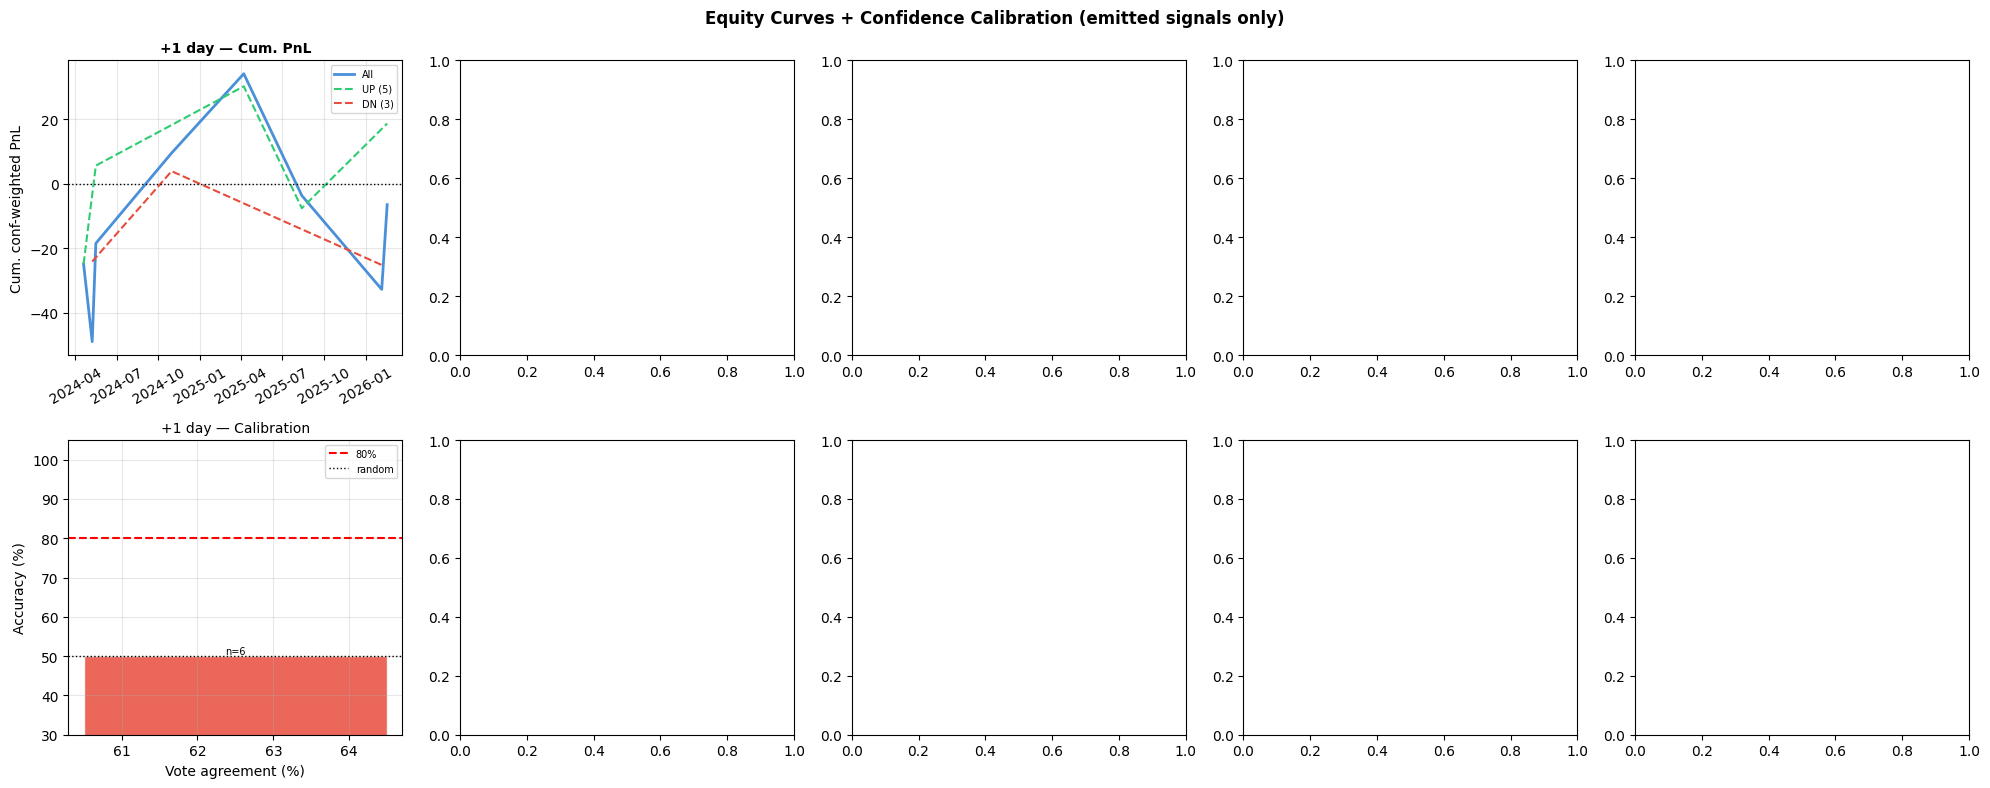

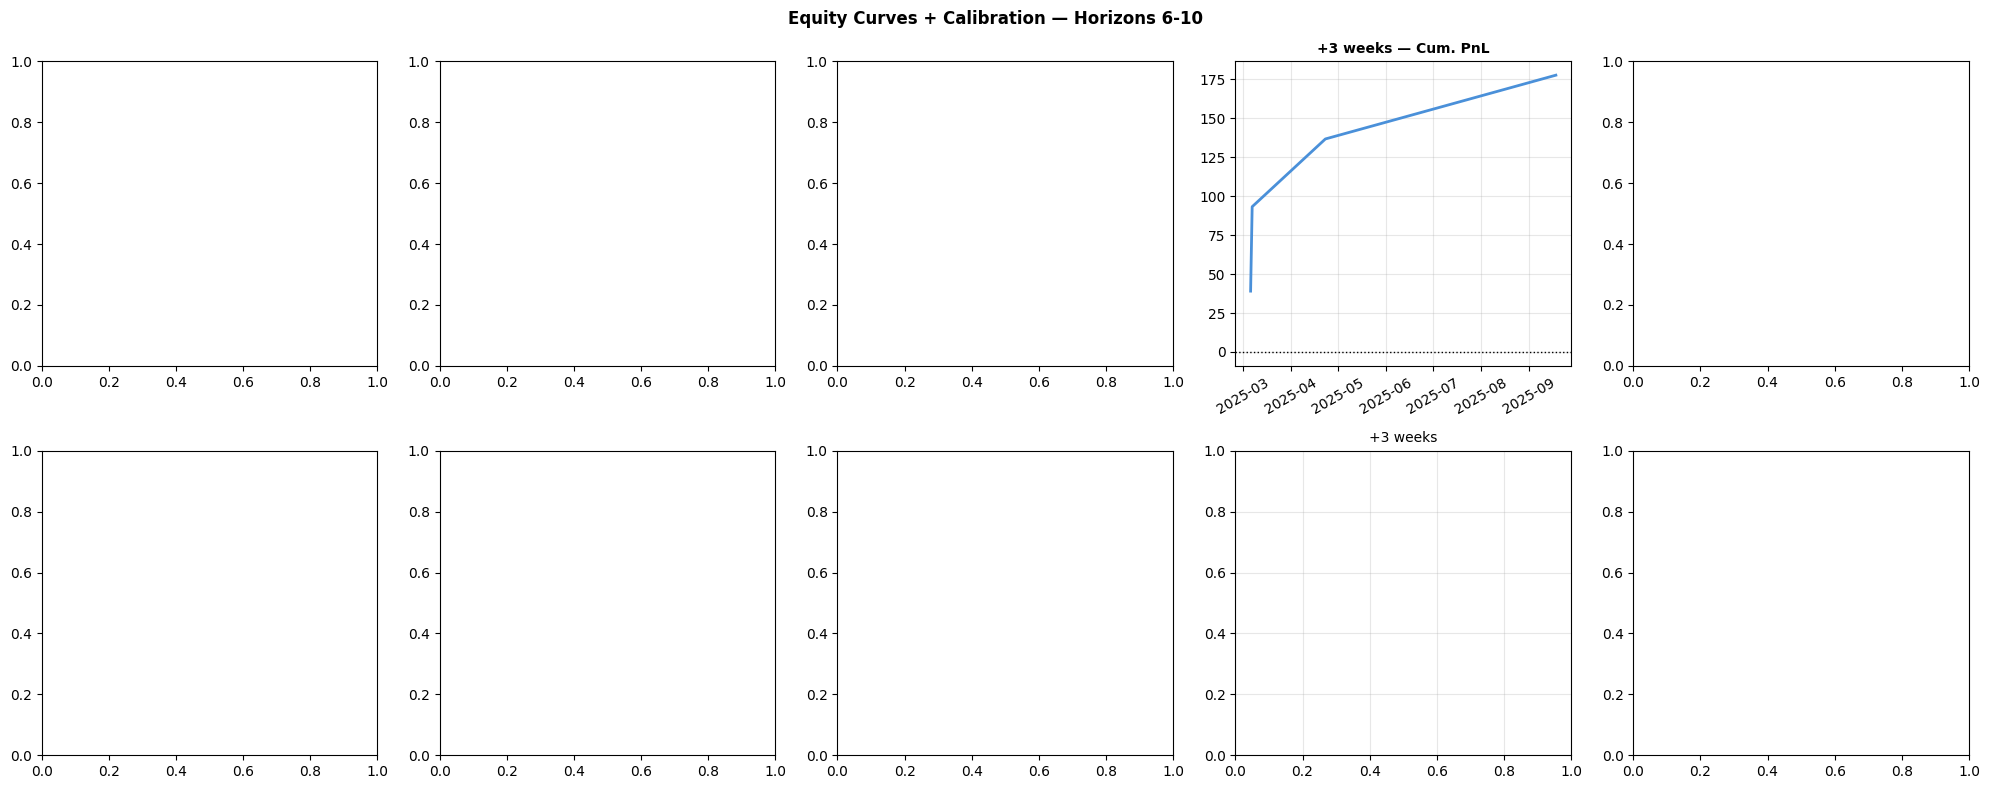

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
# DIAGNOSTIC: Per-direction accuracy, equity curve, confidence calibration
# ══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*90}")
print(f"{'PER-DIRECTION ACCURACY BREAKDOWN':^90}")
print(f"{'='*90}")
print(f"{'Horizon':<14} {'All acc':>8} {'UP acc':>8} {'DN acc':>8} {'#UP':>5} {'#DN':>5} "
      f"{'Bias?':>8}  {'Emitted N':>10}")
print(f"{'-'*90}")

for h_name, res in ALL_RESULTS.items():
    emitted = res[res["emit"] == 1]
    if len(emitted) == 0:
        print(f"{h_name:<14}  (no emitted predictions)")
        continue

    up_rows = emitted[emitted["pred"] == 1]
    dn_rows = emitted[emitted["pred"] == 0]

    all_acc = emitted["correct"].mean() * 100
    up_acc  = up_rows["correct"].mean() * 100 if len(up_rows) > 0 else float("nan")
    dn_acc  = dn_rows["correct"].mean() * 100 if len(dn_rows) > 0 else float("nan")
    n_up    = len(up_rows)
    n_dn    = len(dn_rows)

    # Bias check: should be roughly 50/50 UP/DN predictions with rolling labels
    total   = n_up + n_dn
    up_frac = n_up / max(total, 1)
    if   up_frac > 0.80: bias = "UP-biased"
    elif up_frac < 0.20: bias = "DN-biased"
    else:                bias = "balanced"

    print(f"{h_name:<14} {all_acc:>7.1f}% {up_acc:>7.1f}% {dn_acc:>7.1f}% "
          f"{n_up:>5} {n_dn:>5} {bias:>10}  {total:>10}")

# ── Equity curve simulation ────────────────────────────────────────────────
# Simple strategy: +conf when correct, -conf when wrong (confidence-weighted PnL proxy)
print(f"\n{'='*90}")
print(f"{'EQUITY CURVE — EMITTED SIGNALS ONLY (confidence-weighted)':^90}")
print(f"{'='*90}")

fig, axes = plt.subplots(2, min(len(ALL_RESULTS), 5), figsize=(20, 8))
if len(ALL_RESULTS) == 1:
    axes = np.array(axes).reshape(2, 1)
axes = np.atleast_2d(axes)

for col_i, (h_name, res) in enumerate(ALL_RESULTS.items()):
    if col_i >= 5:
        break
    emitted = res[res["emit"] == 1].copy()
    if len(emitted) < 3:
        continue

    ax_eq = axes[0, col_i]
    ax_cal = axes[1, col_i]

    # Confidence-weighted equity: +conf if correct, -conf if wrong
    emitted["conf"]   = (emitted["agreement"] - 0.5) * 200      # 0-100%
    emitted["pnl"]    = emitted.apply(
        lambda r: r["conf"] if r["correct"] else -r["conf"], axis=1)
    emitted["cumPnL"] = emitted["pnl"].cumsum()

    # Split by direction
    up_e  = emitted[emitted["pred"] == 1]
    dn_e  = emitted[emitted["pred"] == 0]

    ax_eq.plot(emitted.index, emitted["cumPnL"], color="#4a90d9", lw=2, label="All")
    if len(up_e) > 0:
        ax_eq.plot(up_e.index, up_e["pnl"].cumsum(), color="#2ecc71",
                   lw=1.5, ls="--", label=f"UP ({len(up_e)})")
    if len(dn_e) > 0:
        ax_eq.plot(dn_e.index, dn_e["pnl"].cumsum(), color="#e74c3c",
                   lw=1.5, ls="--", label=f"DN ({len(dn_e)})")
    ax_eq.axhline(0, color="black", lw=1, ls=":")
    ax_eq.set_title(f"{h_name} — Cum. PnL", fontsize=10, fontweight="bold")
    ax_eq.set_ylabel("Cum. conf-weighted PnL"); ax_eq.legend(fontsize=7)
    ax_eq.grid(alpha=0.3)
    ax_eq.xaxis.set_tick_params(rotation=30)

    # Calibration: bin by agreement level, plot accuracy per bin
    bins = np.arange(0.50, 0.95, 0.05)
    bin_accs, bin_covs, bin_centers = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        bucket = emitted[(emitted["agreement"] >= lo) & (emitted["agreement"] < hi)]
        if len(bucket) >= 3:
            bin_accs.append(bucket["correct"].mean() * 100)
            bin_covs.append(len(bucket))
            bin_centers.append((lo + hi) / 2 * 100)

    if bin_centers:
        bar_colors = ["#2ecc71" if a >= 75 else "#f39c12" if a >= 60 else "#e74c3c"
                      for a in bin_accs]
        ax_cal.bar(bin_centers, bin_accs, width=4, color=bar_colors, alpha=0.85, edgecolor="white")
        ax_cal.axhline(80, color="red",    lw=1.5, ls="--", label="80%")
        ax_cal.axhline(50, color="black",  lw=1,   ls=":",  label="random")
        for bc, ba, bn in zip(bin_centers, bin_accs, bin_covs):
            ax_cal.text(bc, ba + 0.5, f"n={bn}", ha="center", fontsize=7)
        ax_cal.set_xlabel("Vote agreement (%)"); ax_cal.set_ylabel("Accuracy (%)")
        ax_cal.set_title(f"{h_name} — Calibration", fontsize=10)
        ax_cal.set_ylim(30, 105); ax_cal.legend(fontsize=7); ax_cal.grid(alpha=0.3)

plt.suptitle("Equity Curves + Confidence Calibration (emitted signals only)", fontweight="bold")
plt.tight_layout(); plt.show()

# Second row of horizons (if >5)
if len(ALL_RESULTS) > 5:
    fig2, axes2 = plt.subplots(2, len(ALL_RESULTS)-5, figsize=(4*(len(ALL_RESULTS)-5), 8))
    axes2 = np.atleast_2d(np.array(axes2).reshape(2, len(ALL_RESULTS)-5))
    for col_i, (h_name, res) in enumerate(list(ALL_RESULTS.items())[5:]):
        emitted = res[res["emit"] == 1].copy()
        if len(emitted) < 3:
            continue
        ax_eq  = axes2[0, col_i]
        ax_cal = axes2[1, col_i]
        emitted["conf"]   = (emitted["agreement"] - 0.5) * 200
        emitted["pnl"]    = emitted.apply(lambda r: r["conf"] if r["correct"] else -r["conf"], axis=1)
        emitted["cumPnL"] = emitted["pnl"].cumsum()
        ax_eq.plot(emitted.index, emitted["cumPnL"], color="#4a90d9", lw=2)
        ax_eq.axhline(0, color="black", lw=1, ls=":")
        ax_eq.set_title(f"{h_name} — Cum. PnL", fontsize=10, fontweight="bold")
        ax_eq.grid(alpha=0.3)
        ax_eq.xaxis.set_tick_params(rotation=30)
        ax_cal.set_title(f"{h_name}", fontsize=10); ax_cal.grid(alpha=0.3)
    fig2.suptitle("Equity Curves + Calibration — Horizons 6-10", fontweight="bold")
    fig2.tight_layout(); plt.show()


## 7c. Backtest simulation — realised P&L on test period (2024-now)

For each emitted signal: enter at close of signal day, hold `h_days`, exit at close.
Metrics: hit rate (directional), cumulative log-return, annualised Sharpe, max drawdown, monthly P&L.

**This is the ground-truth check**: if signals have 75-80% directional accuracy but the P&L is flat,
the model only catches small moves (noise). If P&L is strongly positive, signals catch real moves.


                            BACKTEST SIMULATION — TEST PERIOD                             
Horizon            N    Hit%  UP hit  DN hit   CumRet   Sharpe    MaxDD
------------------------------------------------------------------------------------------
+1 day             8   50.0%   60.0%   33.3%     0.2%     0.21    -3.0%
CumRet = sum of log-returns on all trades (no costs, no position sizing)
Sharpe = annualised (assuming trades occur every h_days)


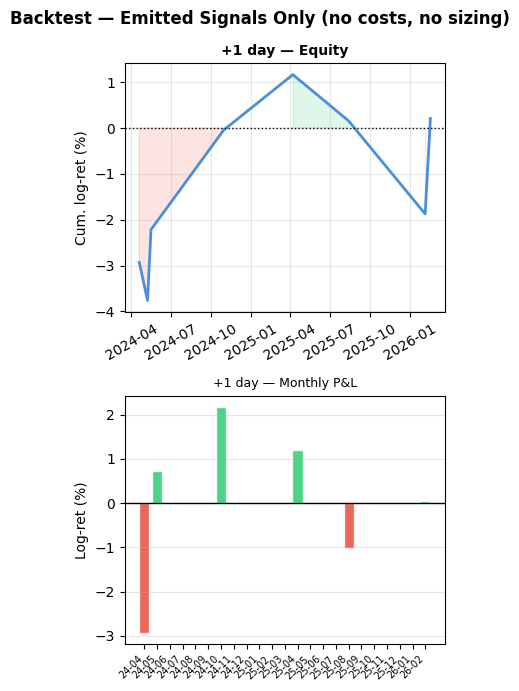

In [17]:
# ══════════════════════════════════════════════════════════════════════════════
# BACKTEST SIMULATION — emitted signals only, test period
# Simulates: enter on close of signal day, hold h_days, exit on close
# Reports: PnL, Sharpe, max drawdown, win rate by direction, monthly P&L
# NOTE: No transaction costs. Signals are directional, not magnitude-weighted.
# ══════════════════════════════════════════════════════════════════════════════

print(f"\n{'='*90}")
print(f"{'BACKTEST SIMULATION — TEST PERIOD':^90}")
print(f"{'='*90}")
print(f"{'Horizon':<14} {'N':>5} {'Hit%':>7} {'UP hit':>7} {'DN hit':>7} "
      f"{'CumRet':>8} {'Sharpe':>8} {'MaxDD':>8}")
print(f"{'-'*90}")

backtest_all = {}

for h_name, h_days in HORIZONS.items():
    if h_name not in ALL_RESULTS:
        continue
    res = ALL_RESULTS[h_name]
    emitted = res[res["emit"] == 1].copy()
    if len(emitted) < 5:
        continue

    # Get the actual log-return for each emitted signal over h_days
    pnl_rows = []
    for sig_date, row in emitted.iterrows():
        try:
            # Find index of signal date in df
            if sig_date not in df.index:
                continue
            i = df.index.get_loc(sig_date)
            exit_i = min(i + h_days, len(df) - 1)
            actual_ret = np.log(df["Close"].iloc[exit_i] / df["Close"].iloc[i])
            direction  = 1 if row["pred"] == 1 else -1   # +1=long, -1=short
            trade_pnl  = direction * actual_ret           # signed return
            pnl_rows.append({
                "date":      sig_date,
                "ret":       actual_ret,
                "direction": direction,
                "pnl":       trade_pnl,
                "pred":      int(row["pred"]),
                "correct":   int(row["correct"]),
                "conf":      float(row["agreement"]),
            })
        except (KeyError, IndexError):
            continue

    if not pnl_rows:
        continue

    bt = pd.DataFrame(pnl_rows).set_index("date")
    bt["cum_pnl"] = bt["pnl"].cumsum()

    # Metrics
    n          = len(bt)
    hit_rate   = (bt["pnl"] > 0).mean() * 100
    up_hits    = bt[bt["direction"]==1]
    dn_hits    = bt[bt["direction"]==-1]
    up_hit_r   = (up_hits["pnl"] > 0).mean()*100 if len(up_hits) > 0 else float("nan")
    dn_hit_r   = (dn_hits["pnl"] > 0).mean()*100 if len(dn_hits) > 0 else float("nan")
    cum_ret    = bt["pnl"].sum() * 100
    # Annualised Sharpe: assume trades roughly every h_days
    mean_ret   = bt["pnl"].mean()
    std_ret    = bt["pnl"].std() + 1e-9
    trades_pa  = 252 / max(h_days, 1)
    sharpe     = (mean_ret / std_ret) * np.sqrt(trades_pa)
    # Max drawdown from cumulative PnL
    roll_max   = bt["cum_pnl"].cummax()
    drawdown   = (bt["cum_pnl"] - roll_max)
    max_dd     = drawdown.min() * 100

    backtest_all[h_name] = bt
    print(f"{h_name:<14} {n:>5} {hit_rate:>6.1f}% {up_hit_r:>6.1f}% {dn_hit_r:>6.1f}% "
          f"{cum_ret:>7.1f}% {sharpe:>8.2f} {max_dd:>7.1f}%")

print(f"{'='*90}")
print("CumRet = sum of log-returns on all trades (no costs, no position sizing)")
print("Sharpe = annualised (assuming trades occur every h_days)")

# ── Equity curve plots ────────────────────────────────────────────────────────
n_bt = len(backtest_all)
if n_bt > 0:
    ncols = min(n_bt, 5)
    nrows = 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 7))
    axes = np.array(axes).reshape(nrows, ncols)

    for col_i, (h_name, bt) in enumerate(list(backtest_all.items())[:5]):
        ax_eq  = axes[0, col_i]
        ax_mth = axes[1, col_i]

        # Equity curve, coloured by UP/DN
        up_bt = bt[bt["direction"] ==  1]["cum_pnl"]
        dn_bt = bt[bt["direction"] == -1]["cum_pnl"]

        ax_eq.plot(bt.index, bt["cum_pnl"]*100, color="#4a90d9", lw=2, label="All")
        ax_eq.fill_between(bt.index, bt["cum_pnl"]*100, 0,
                           where=bt["cum_pnl"] >= 0, alpha=0.15, color="#2ecc71")
        ax_eq.fill_between(bt.index, bt["cum_pnl"]*100, 0,
                           where=bt["cum_pnl"] < 0, alpha=0.15, color="#e74c3c")
        ax_eq.axhline(0, color="black", lw=1, ls=":")
        ax_eq.set_title(f"{h_name} — Equity", fontsize=10, fontweight="bold")
        ax_eq.set_ylabel("Cum. log-ret (%)"); ax_eq.grid(alpha=0.3)
        ax_eq.tick_params(axis="x", rotation=30)

        # Monthly PnL bar chart
        bt_copy = bt.copy()
        bt_copy.index = pd.to_datetime(bt_copy.index)
        monthly = bt_copy["pnl"].resample("ME").sum() * 100
        mth_colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in monthly.values]
        ax_mth.bar(range(len(monthly)), monthly.values, color=mth_colors, alpha=0.85, edgecolor="white")
        ax_mth.axhline(0, color="black", lw=1)
        ax_mth.set_xticks(range(len(monthly)))
        ax_mth.set_xticklabels([d.strftime("%y-%m") for d in monthly.index],
                                rotation=45, ha="right", fontsize=7)
        ax_mth.set_title(f"{h_name} — Monthly P&L", fontsize=9)
        ax_mth.set_ylabel("Log-ret (%)"); ax_mth.grid(axis="y", alpha=0.3)

    plt.suptitle("Backtest — Emitted Signals Only (no costs, no sizing)", fontweight="bold")
    plt.tight_layout(); plt.show()

    # Second row of horizons if > 5
    if n_bt > 5:
        items2 = list(backtest_all.items())[5:]
        fig2, axes2 = plt.subplots(2, len(items2), figsize=(4*len(items2), 7))
        axes2 = np.array(axes2).reshape(2, len(items2))
        for col_i, (h_name, bt) in enumerate(items2):
            axes2[0, col_i].plot(bt.index, bt["cum_pnl"]*100, color="#4a90d9", lw=2)
            axes2[0, col_i].axhline(0, color="black", lw=1, ls=":")
            axes2[0, col_i].set_title(f"{h_name}", fontsize=10, fontweight="bold")
            axes2[0, col_i].grid(alpha=0.3)
            bt_copy = bt.copy()
            bt_copy.index = pd.to_datetime(bt_copy.index)
            monthly = bt_copy["pnl"].resample("ME").sum() * 100
            mth_colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in monthly.values]
            axes2[1, col_i].bar(range(len(monthly)), monthly.values, color=mth_colors, alpha=0.85)
            axes2[1, col_i].axhline(0, color="black", lw=1)
            axes2[1, col_i].set_title(f"{h_name} monthly", fontsize=9)
            axes2[1, col_i].grid(axis="y", alpha=0.3)
        fig2.tight_layout(); plt.show()


## 8. Today's predictions — all 10 horizons (with meta-learner)


  XAU/EUR  |  2026-03-20  |  3,952.26 EUR  |  1y: +42.4%
  Regime:  ACTIVE — model may speak
Horizon         VoteAgr  DivOK Signal              Conf bar   Action    (UP/DN votes)
------------------------------------------------------------------------------------
+1 day            62.7%    YES  STRONG UP     [██░░░░░░░░]  25%  EMIT ▲    (18↑/7↓) M
+2 days           72.0%     NO  unanimous(23v2)  [████░░░░░░]  44%  BIAS-skip (23↑/2↓) M
+3 days           80.1%     NO  unanimous(25v0)  [██████░░░░]  60%  BIAS-skip (25↑/0↓) M
+4 days           89.0%     NO  unanimous(25v0)  [███████░░░]  78%  BIAS-skip (25↑/0↓) M
+5 days           87.8%     NO  unanimous(25v0)  [███████░░░]  76%  BIAS-skip (25↑/0↓) M
+6 days           93.4%     NO  unanimous(25v0)  [████████░░]  87%  BIAS-skip (25↑/0↓) M
+7 days           92.8%     NO  unanimous(25v0)  [████████░░]  86%  BIAS-skip (25↑/0↓) M
+2 weeks          93.8%     NO  unanimous(25v0)  [████████░░]  88%  BIAS-skip (25↑/0↓) M
+3 weeks          89.5%   

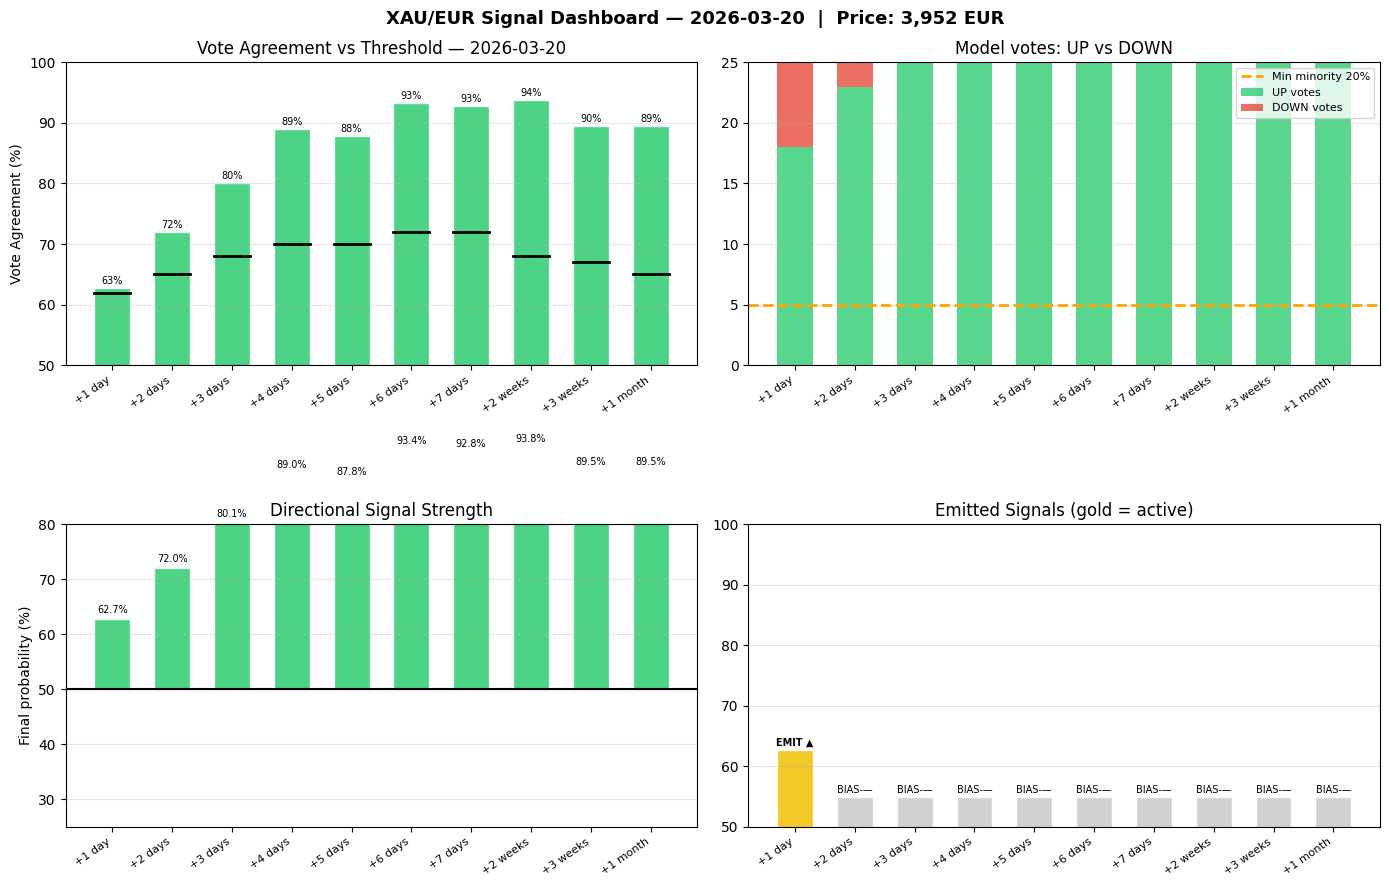

In [18]:
latest_feat = df[FEAT].iloc[-1:].values.astype(np.float32)
latest_reg  = is_predictable(df.iloc[-1])
price       = df["Close"].iloc[-1]
today       = df.index[-1].date()
price_1y    = df["Close"].iloc[-252] if len(df) > 252 else df["Close"].iloc[0]
ytd_ret     = (price / price_1y - 1) * 100

print(f"\n{'='*84}")
print(f"  XAU/EUR  |  {today}  |  {price:,.2f} EUR  |  1y: {ytd_ret:+.1f}%")
print(f"  Regime:  {'ACTIVE — model may speak' if latest_reg else 'QUIET — model stays silent'}")
print(f"{'='*84}")
print(f"{'Horizon':<14} {'VoteAgr':>8} {'DivOK':>6} {'Signal':<18}  Conf bar   Action    (UP/DN votes)")
print(f"{'-'*84}")

results_today = {}
for h_name, mdict in FINAL_MODELS.items():
    vote_thr = HORIZON_VOTE_THRESHOLDS[h_name]
    trained  = mdict["base"]
    meta_lr  = mdict["meta"]
    if not trained:
        continue

    raw_w   = np.clip(np.array([t[3] for t in trained], dtype=float), 0.4, 1.0)
    weights = raw_w / raw_w.sum()

    base_probs = np.array([
        clf.predict_proba(sc.transform(latest_feat))[0, 1]
        for clf, sc, q, w in trained
    ])
    vote_mean = float(np.dot(weights, base_probs))

    # Apply meta-learner if available
    if meta_lr is not None:
        try:
            meta_p  = meta_lr.predict_proba(base_probs.reshape(1, -1))[0, 1]
            final_p = 0.70 * vote_mean + 0.30 * meta_p
        except Exception:
            final_p = vote_mean
    else:
        final_p = vote_mean

    agr      = max(final_p, 1 - final_p)
    div_ok   = direction_diversity_ok(base_probs)
    n_up     = int((base_probs >= 0.5).sum())
    n_dn     = len(base_probs) - n_up
    conf_pct = (agr - 0.5) * 200
    bar      = "█" * int(conf_pct / 10) + "░" * (10 - int(conf_pct / 10))

    if   agr >= vote_thr and div_ok and final_p >= 0.5 and latest_reg:  sig="STRONG UP   "; action="EMIT ▲"
    elif agr >= vote_thr and div_ok and final_p <  0.5 and latest_reg:  sig="STRONG DOWN "; action="EMIT ▼"
    elif agr >= vote_thr and div_ok and final_p >= 0.5:                 sig="UP (no rgm) "; action="skip"
    elif agr >= vote_thr and div_ok and final_p <  0.5:                 sig="DOWN(no rgm)"; action="skip"
    elif not div_ok:                                                      sig=f"unanimous({n_up}v{n_dn})"; action="BIAS-skip"
    elif final_p >= 0.55:                                                 sig="weak up     "; action="skip"
    elif final_p <= 0.45:                                                 sig="weak down   "; action="skip"
    else:                                                                 sig="uncertain   "; action="skip"

    results_today[h_name] = {
        "final_p": final_p, "vm": vote_mean, "agr": agr,
        "div_ok": div_ok, "sig": sig, "action": action,
        "n_up": n_up, "n_dn": n_dn, "meta_used": meta_lr is not None
    }

    meta_flag = "M" if meta_lr is not None else " "
    print(f"{h_name:<14} {agr*100:>7.1f}% {'YES' if div_ok else 'NO':>6}  {sig}  [{bar}]{conf_pct:4.0f}%  "
          f"{action:<10}({n_up}↑/{n_dn}↓) {meta_flag}")

print(f"{'='*84}")
print(f"M = meta-learner active  |  Diversity gate: ≥{MIN_MINORITY_FRAC*100:.0f}% minority required")
print("NOT financial advice.")

# ── Summary dashboard ──────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

h_names  = list(results_today.keys())
agrs     = [results_today[h]["agr"] * 100   for h in h_names]
vms      = [results_today[h]["final_p"]*100 for h in h_names]
n_ups    = [results_today[h]["n_up"]        for h in h_names]
n_dns    = [results_today[h]["n_dn"]        for h in h_names]
thrs     = [HORIZON_VOTE_THRESHOLDS[h]*100  for h in h_names]
colors   = ["#2ecc71" if results_today[h]["final_p"]>=0.5 else "#e74c3c" for h in h_names]
emit_clr = ["#f1c40f" if results_today[h]["action"].startswith("EMIT") else "#cccccc"
            for h in h_names]
x        = np.arange(len(h_names))

# Plot 1: Agreement vs threshold
axes[0,0].bar(x, agrs, color=colors, alpha=0.85, edgecolor="white", width=0.6)
for i, (a, t) in enumerate(zip(agrs, thrs)):
    axes[0,0].plot([i-0.3, i+0.3], [t, t], color="black", lw=2)
axes[0,0].set_xticks(x); axes[0,0].set_xticklabels(h_names, rotation=35, ha="right", fontsize=8)
axes[0,0].set_ylabel("Vote Agreement (%)"); axes[0,0].set_ylim(50, 100)
axes[0,0].set_title(f"Vote Agreement vs Threshold — {today}")
axes[0,0].grid(axis="y", alpha=0.3)
for bi, a in enumerate(agrs):
    axes[0,0].text(x[bi], a+0.3, f"{a:.0f}%", ha="center", va="bottom", fontsize=7)

# Plot 2: UP vs DOWN vote counts
axes[0,1].bar(x, n_ups, label="UP votes",   color="#2ecc71", alpha=0.8, width=0.6)
axes[0,1].bar(x, n_dns, bottom=n_ups, label="DOWN votes", color="#e74c3c", alpha=0.8, width=0.6)
total_n = max(n_ups[0]+n_dns[0], 1)
axes[0,1].axhline(total_n*MIN_MINORITY_FRAC, color="orange", ls="--", lw=2,
                  label=f"Min minority {MIN_MINORITY_FRAC*100:.0f}%")
axes[0,1].set_xticks(x); axes[0,1].set_xticklabels(h_names, rotation=35, ha="right", fontsize=8)
axes[0,1].set_title("Model votes: UP vs DOWN"); axes[0,1].legend(fontsize=8)
axes[0,1].grid(axis="y", alpha=0.3)

# Plot 3: Directional probability
axes[1,0].bar(x, [v-50 for v in vms], color=colors, alpha=0.85, edgecolor="white", width=0.6, bottom=50)
axes[1,0].axhline(50, color="black", lw=1.5)
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(h_names, rotation=35, ha="right", fontsize=8)
axes[1,0].set_ylabel("Final probability (%)"); axes[1,0].set_ylim(25, 80)
axes[1,0].set_title("Directional Signal Strength")
axes[1,0].grid(axis="y", alpha=0.3)
for bi, vm in enumerate(vms):
    axes[1,0].text(x[bi], vm+(0.8 if vm>50 else -1.5), f"{vm:.1f}%",
                   ha="center", va="bottom" if vm>50 else "top", fontsize=7)

# Plot 4: EMIT summary
signal_labels = [results_today[h]["action"] for h in h_names]
emit_flags    = [1 if "EMIT" in a else 0 for a in signal_labels]
bar_heights   = [agrs[i] if emit_flags[i] else 55 for i in range(len(h_names))]
axes[1,1].bar(x, bar_heights, color=emit_clr, edgecolor="white", width=0.6, alpha=0.9)
for bi, (sl, ag) in enumerate(zip(signal_labels, bar_heights)):
    axes[1,1].text(x[bi], ag+0.3, sl.replace("skip","—").strip(),
                   ha="center", va="bottom", fontsize=7,
                   fontweight="bold" if "EMIT" in sl else "normal")
axes[1,1].set_xticks(x); axes[1,1].set_xticklabels(h_names, rotation=35, ha="right", fontsize=8)
axes[1,1].set_ylim(50, 100); axes[1,1].set_title("Emitted Signals (gold = active)")
axes[1,1].grid(axis="y", alpha=0.3)

plt.suptitle(f"XAU/EUR Signal Dashboard — {today}  |  Price: {price:,.0f} EUR",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()


## 9. Feature importance — aggregated across all LightGBM models

Computing feature importance across all LightGBM final models...

Top 30 features (averaged across 150 LightGBM models):
ichi_cloud_w        210.720000
gsr                 199.833333
dxy_r1              164.326667
gold_dxy_corr20     163.580000
vol60               161.993333
ema200d             161.380000
skew20              153.466667
gold_gdx_ratio_z    148.240000
mfi14               141.006667
autocorr5           139.266667
gold_spx_corr20     129.466667
kurt20              129.360000
lr_slope60          114.240000
vol20               112.486667
vix_lvl             104.273333
month_cyc           101.546667
gold_gdx_corr20      99.766667
zsc252               99.406667
gold_tlt_corr20      95.360000
ag_r20               92.033333
dist252h             91.166667
adx                  90.560000
month_cyc2           88.446667
spx_vol5             84.833333
dxy_corr_chg         83.533333
vix_z60              79.993333
slope_accel          79.433333
vol_trend            79.140000
bb_w20     

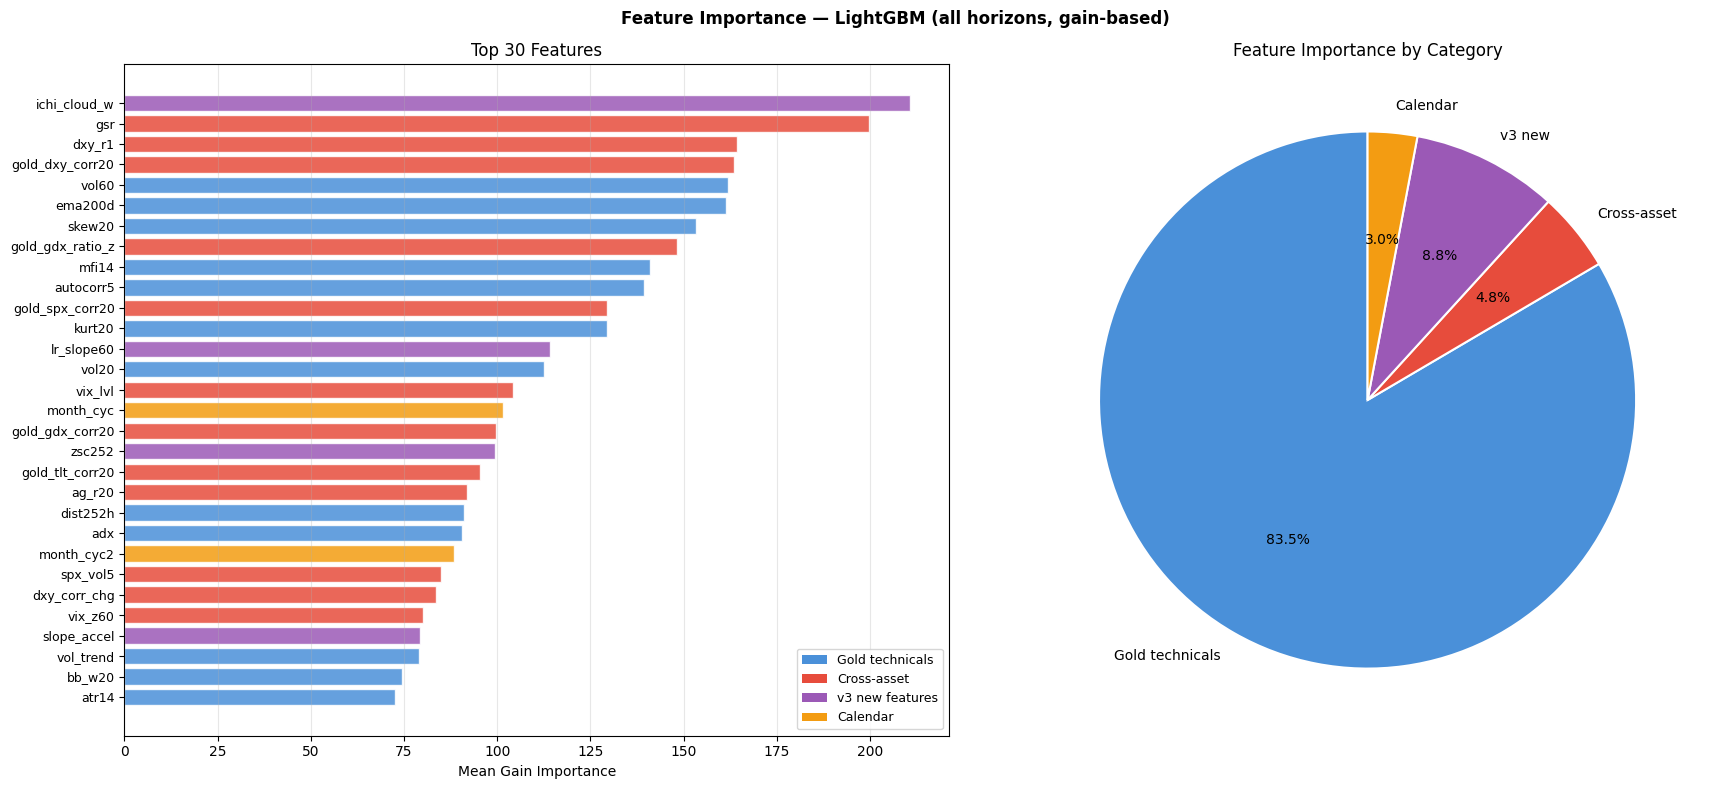

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# FEATURE IMPORTANCE — aggregated across all LightGBM final models
# Uses split-based importance (robust to feature scale differences)
# ══════════════════════════════════════════════════════════════════════════════

print("Computing feature importance across all LightGBM final models...")

# Aggregate gain-based importance across all LGBM models and all horizons
importance_sum = np.zeros(len(FEAT))

lgbm_count = 0
for h_name, mdict in FINAL_MODELS.items():
    for clf, sc, q, w in mdict["base"]:
        if isinstance(clf, LGBMClassifier):
            importance_sum += clf.feature_importances_
            lgbm_count += 1

if lgbm_count == 0:
    print("No LightGBM models found.")
else:
    importance_mean = importance_sum / lgbm_count
    feat_imp = pd.Series(importance_mean, index=FEAT).sort_values(ascending=False)

    print(f"\nTop 30 features (averaged across {lgbm_count} LightGBM models):")
    print(feat_imp.head(30).to_string())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

    # Top 30 overall
    top30 = feat_imp.head(30)
    colors = []
    for feat in top30.index:
        if any(feat.startswith(p) for p in ["gdx","spx","dxy","vix","tlt","ag_","gsr","gold_"]):
            colors.append("#e74c3c")   # cross-asset = red
        elif any(feat.startswith(p) for p in ["ichi","fisher","kc_","dc_","vwap","posc","lr_","slope","rsi_div","zsc252"]):
            colors.append("#9b59b6")   # v3 new = purple
        elif any(feat.startswith(p) for p in ["dow","month","is_","quarter"]):
            colors.append("#f39c12")   # calendar = orange
        else:
            colors.append("#4a90d9")   # gold technicals = blue

    ax1.barh(range(len(top30)), top30.values[::-1],
             color=colors[::-1], alpha=0.85, edgecolor="white")
    ax1.set_yticks(range(len(top30)))
    ax1.set_yticklabels(top30.index[::-1], fontsize=9)
    ax1.set_xlabel("Mean Gain Importance"); ax1.set_title("Top 30 Features")
    ax1.grid(axis="x", alpha=0.3)

    # Legend
    from matplotlib.patches import Patch
    legend_els = [
        Patch(facecolor="#4a90d9", label="Gold technicals"),
        Patch(facecolor="#e74c3c", label="Cross-asset"),
        Patch(facecolor="#9b59b6", label="v3 new features"),
        Patch(facecolor="#f39c12", label="Calendar"),
    ]
    ax1.legend(handles=legend_els, fontsize=9, loc="lower right")

    # Feature category breakdown
    cat_names = ["Gold technicals", "Cross-asset", "v3 new", "Calendar"]
    cat_masks = [
        [not any(f.startswith(p) for p in ["gdx","spx","dxy","vix","tlt","ag_","gsr","gold_",
                                            "ichi","fisher","kc_","dc_","vwap","posc","lr_","slope",
                                            "rsi_div","zsc252","dow","month","is_","quarter"])
         for f in FEAT],
        [any(f.startswith(p) for p in ["gdx","spx","dxy","vix","tlt","ag_","gsr","gold_"]) for f in FEAT],
        [any(f.startswith(p) for p in ["ichi","fisher","kc_","dc_","vwap","posc","lr_","slope","rsi_div","zsc252"]) for f in FEAT],
        [any(f.startswith(p) for p in ["dow","month","is_","quarter"]) for f in FEAT],
    ]
    cat_totals = [feat_imp[mask].sum() for mask in cat_masks]
    ax2.pie(cat_totals, labels=cat_names,
            colors=["#4a90d9","#e74c3c","#9b59b6","#f39c12"],
            autopct="%1.1f%%", startangle=90,
            wedgeprops={"edgecolor":"white","linewidth":1.5})
    ax2.set_title("Feature Importance by Category")

    plt.suptitle("Feature Importance — LightGBM (all horizons, gain-based)", fontweight="bold")
    plt.tight_layout(); plt.show()


## 10. Per-horizon threshold tuning

In [20]:
print("Per-horizon accuracy vs vote threshold (in-regime, diversity-ok days only):")
print(f"{'Horizon':<14} {'CurrThr':>8} {'Acc@Thr':>9} {'BestThr':>9} {'BestAcc':>9}")
print("-"*55)

for h_name, res in ALL_RESULTS.items():
    vote_thr = HORIZON_VOTE_THRESHOLDS[h_name]
    gate = res[(res["agreement"]>=vote_thr) & (res["in_regime"]==1) & (res["div_ok"]==1)]
    acc_at_thr = gate["correct"].mean()*100 if len(gate) >= 5 else 0

    best_thr, best_acc = vote_thr, acc_at_thr
    for thr in np.arange(0.55, 0.95, 0.01):
        g2 = res[(res["agreement"]>=thr) & (res["in_regime"]==1) & (res["div_ok"]==1)]
        if len(g2) < 5: break
        a2 = g2["correct"].mean()*100
        if a2 > best_acc:
            best_acc = a2; best_thr = thr
    print(f"{h_name:<14} {vote_thr:>8.2f} {acc_at_thr:>8.1f}% {best_thr:>8.2f} {best_acc:>8.1f}%")

print("\nAll-horizon combined (in-regime + diversity-ok):")
print(f"{'Threshold':>10} {'Coverage':>9} {'Accuracy':>10} {'N':>6}")
print("-"*42)
all_rows = []
for h_name, res in ALL_RESULTS.items():
    for _, row in res.iterrows():
        all_rows.append(row.to_dict())
all_df = pd.DataFrame(all_rows)

for thr in np.arange(0.55, 0.95, 0.025):
    gate = all_df[(all_df["agreement"]>=thr) & (all_df["in_regime"]==1) & (all_df["div_ok"]==1)]
    if len(gate) < 10: break
    total = len(all_df[(all_df["in_regime"]==1) & (all_df["div_ok"]==1)])
    cov   = len(gate)/max(total,1)*100
    acc   = gate["correct"].mean()*100
    star  = "  <- recommended" if 78<=acc<=88 else ""
    print(f"{thr:>10.3f} {cov:>8.0f}% {acc:>9.1f}% {len(gate):>6}{star}")


Per-horizon accuracy vs vote threshold (in-regime, diversity-ok days only):
Horizon         CurrThr   Acc@Thr   BestThr   BestAcc
-------------------------------------------------------
+1 day             0.62     50.0%     0.55     64.3%
+2 days            0.65      0.0%     0.59     50.0%
+3 days            0.68      0.0%     0.65     80.0%
+4 days            0.70      0.0%     0.58     63.6%
+5 days            0.70      0.0%     0.61     66.7%
+6 days            0.72      0.0%     0.55     80.0%
+7 days            0.72      0.0%     0.61     83.3%
+2 weeks           0.68      0.0%     0.59     57.1%
+3 weeks           0.67      0.0%     0.55    100.0%
+1 month           0.65      0.0%     0.65      0.0%

All-horizon combined (in-regime + diversity-ok):
 Threshold  Coverage   Accuracy      N
------------------------------------------
     0.550       65%      59.2%    157
     0.575       45%      60.9%    110
     0.600       28%      57.4%     68
     0.625       18%      68.2%    

## 11. Save models

In [21]:
os.makedirs("xaueur_v3", exist_ok=True)
for h_name, mdict in FINAL_MODELS.items():
    safe = h_name.replace(" ","_").replace("+","p")
    with open(f"xaueur_v3/{safe}.pkl","wb") as f:
        pickle.dump({
            "base_models":          mdict["base"],
            "meta":                 mdict["meta"],
            "features":             FEAT,
            "vote_threshold":       HORIZON_VOTE_THRESHOLDS[h_name],
            "min_minority_frac":    MIN_MINORITY_FRAC,
            "regime_adx":           REGIME_ADX_MIN,
            "regime_vix":           REGIME_VIX_ZSCORE,
            "rolling_label_window": ROLLING_LABEL_WINDOW,
            "label_quantiles":      LABEL_QUANTILES,
        }, f)
print("All models saved to xaueur_v3/")
print("\nUsage:")
print("  d = pickle.load(open('xaueur_v3/p1_day.pkl','rb'))")
print("  base_probs = [m.predict_proba(sc.transform(X))[0,1] for m,sc,q,w in d['base_models']]")
print("  vote_mean  = np.mean(base_probs)")
print("  n_up = sum(p>=0.5 for p in base_probs)")
print("  n_dn = len(base_probs) - n_up")
print("  div_ok = min(n_up, n_dn) / len(base_probs) >= d['min_minority_frac']")
print("  emit = (max(vote_mean,1-vote_mean) >= d['vote_threshold']) and div_ok")


All models saved to xaueur_v3/

Usage:
  d = pickle.load(open('xaueur_v3/p1_day.pkl','rb'))
  base_probs = [m.predict_proba(sc.transform(X))[0,1] for m,sc,q,w in d['base_models']]
  vote_mean  = np.mean(base_probs)
  n_up = sum(p>=0.5 for p in base_probs)
  n_dn = len(base_probs) - n_up
  div_ok = min(n_up, n_dn) / len(base_probs) >= d['min_minority_frac']
  emit = (max(vote_mean,1-vote_mean) >= d['vote_threshold']) and div_ok


---
# Project Description — XAU/EUR Ensemble Predictor v3

## Overview
Predicts the **directional move** of XAU/EUR (Gold in Euros) across 10 time horizons (+1 day to +1 month). A signal is emitted only when vote agreement, direction diversity, and the market regime filter all pass simultaneously.

---

## v3 vs v2 — What Was Fixed and Why

| Problem in v2 | Root Cause | v3 Fix |
|---|---|---|
| +6d/+7d accuracy < 50% | Fixed 2012-2022 labels; gold 2024-26 was +120% so all labels became UP | Rolling 252d adaptive labels with `shift(1)` |
| Entropy confidence = 99% but useless | All 25 models agreed (UP) → entropy = max, but they were all wrong | Direction diversity gate: ≥20% minority votes required |
| Regime filter passed 80% of days | ADX/VIX thresholds too loose | ADX>22, VIX-z>1.2, vol_ratio>1.25 |
| No genuine model diversity | All boosting used LightGBM algorithm | XGBoost (5 seeds, different engine) added |
| No meta-learning | Base weights = validation accuracy only | Stacking: LogReg on val-window OOF, also for live final models |

---

## Architecture

**25 base models + 1 meta-learner per horizon:**

| Model | Count | Source of diversity |
|---|---|---|
| LightGBM | 15 (3 quantiles × 5 seeds) | Gradient boosting; 3 label thresholds |
| RandomForest | 3 (1 quantile × 3 seeds) | Bagging; independent split randomness |
| ExtraTrees | 2 (1 quantile × 2 seeds) | Maximum feature/split randomisation |
| XGBoost | 5 (1 quantile × 5 seeds) | Different boosting algorithm entirely |
| LogisticRegression meta | 1 | Learns blend from val-window OOF probs |

---

## Rolling Adaptive Labels

```
q_hi[t] = quantile(fut[t-252 : t-1], 1-q)   # only past data, no lookahead
q_lo[t] = quantile(fut[t-252 : t-1],   q)
label = UP   if fut[t] >= q_hi[t]
      = DOWN if fut[t] <= q_lo[t]
      = skip otherwise
```

Quantiles used: 0.12, 0.17, 0.22. Labels are always ≈50% UP / 50% DOWN.

---

## Confidence Gates (all three must pass to emit)

1. **Vote agreement** ≥ per-horizon threshold (0.62 to 0.72)
2. **Direction diversity**: `min(n_up, n_dn) / N_models ≥ 0.20`
3. **Regime**: ADX>22 OR |VIX-z|>1.2 OR vol_ratio>1.25

---

## Features (~135)

**Gold technicals:** returns, RSI, MACD, Bollinger, EMA distances, ATR, ADX, Stochastic, CCI, Williams %R, ROC, vol regime, skew/kurt, candle anatomy, MFI, Ichimoku, Fisher, variance ratio, calendar

**v3 additions:** LR slope + acceleration, Keltner (14/20d), Donchian (20/55d), VWAP deviation, price oscillator, RSI divergence, 252d z-score

**Cross-asset:** Silver, DXY, SPY, VIX, TLT, GDX — returns, correlations, spreads, interactions

---

## Walk-Forward Protocol
- Retrain every 63 days; window = last 1,600 labeled days
- Val window = last 63 days of training (for model weighting + meta)
- Final live models trained on 2012-2023; meta trained on 2023 val
- Test: 2024-01-01 to present

---

**NOT financial advice. Past accuracy does not guarantee future results.**

*v1: LightGBM-only, 4 horizons, fixed labels*
*v2: RF/ET/XGB, 10 horizons, Ichimoku/Fisher/GDX — fixed labels caused UP bias*
*v3: Rolling labels (fixes bias), diversity gate, XGBoost, stacking meta, per-horizon thresholds, full diagnostics*
